<a href="https://colab.research.google.com/github/fesilveiraeng/Trabalho_IA/blob/main/1_PreparaDados_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Conecta ao Google Drive

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip -q install kagglehub

In [ ]:
from kagglehub import KaggleDatasetAdapter
import kagglehub

from sklearn.datasets import fetch_openml

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.decomposition import PCA

from IPython.display import display
from imblearn.under_sampling import RandomUnderSampler

import os
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import numpy as np

In [ ]:
#'''
# Define nome da base
base_name = "CDC"

# Carrega a base
base_data = fetch_openml(data_id=46841, as_frame=True)

# Define o limiar de binarização
limiar = None  # Wine: 6 | CDC: None

# Extrai os dados de um Bunch, quando necessário
if not isinstance(base_data, pd.DataFrame):
    if hasattr(base_data, "frame") and base_data.frame is not None:
        base_data = base_data.frame.copy()
    else:
        base_data = pd.DataFrame(
            base_data.data,
            columns=getattr(base_data, "feature_names", None)
        )
#'''

In [ ]:
'''
# Define nome da base
base_name = "Wine"

# Identificação da base no Kaggle
dataset = "uciml/red-wine-quality-cortez-et-al-2009"
file_path = "winequality-red.csv"

# Carrega a base
base_data = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    dataset,
    file_path
)

# Define o limiar de binarização
limiar = 6  # Wine: 6 | CDC: None
'''

'\n# Define nome da base\nbase_name = "Wine"\n\n# Identificação da base no Kaggle\ndataset = "uciml/red-wine-quality-cortez-et-al-2009"\nfile_path = "winequality-red.csv"\n\n# Carrega a base\nbase_data = kagglehub.dataset_load(\n    KaggleDatasetAdapter.PANDAS,\n    dataset,\n    file_path\n)\n\n# Define o limiar de binarização\nlimiar = 6  # Wine: 6 | CDC: None\n'

In [ ]:
# Define caminho padrão
base_path = "/content/drive/MyDrive/Trabalho_IA/Arquivos/"

# Define colunas para remover
remove_pos_col = [-1]

# Define categorias da base
base_categorias = [-1]

# Define Dados
X = base_data.drop(base_data.columns[remove_pos_col], axis=1)
Y = base_data.iloc[:, base_categorias].values

# Define Binarização, quando necessária
if limiar is not None:
    Y = (Y >= limiar).astype(int)
else:
    Y = Y.astype(int)

# Define o tamanho máximo da amostra
n_amostra = min(10000, len(X))

# Seleciona uma amostra estratificada, quando necessário
if n_amostra < len(X):
    X_amostra, _, Y_amostra, _ = train_test_split(
        X, Y,
        train_size=n_amostra,
        stratify=Y,
        random_state=42
    )
else:
    X_amostra = X
    Y_amostra = Y

In [ ]:
#===============================================
# Análise dos dados

# Identifica a variável-alvo
nome_alvo = base_data.columns[base_categorias[0]]
print("Variável-alvo:", nome_alvo)

# Converte Y para vetor unidimensional
Y = np.asarray(Y).ravel()

# Identifica as classes e suas frequências
classes, quantidades = np.unique(Y, return_counts=True)

# Quantidade de classes
print("Número de classes:", len(classes))

# Organiza a distribuição
distribuicao = pd.DataFrame({
    "Quantidade": quantidades,
    "Proporção (%)": quantidades / quantidades.sum() * 100
}, index=pd.Index(classes, name="Classe"))

# Exibe a distribuição
print("\nDistribuição das classes:")
display(distribuicao.round(2))

#===============================================
# Análise de todos os atributos

# Resumo dos atributos
resumo_atributos = pd.DataFrame({
    "Atributo": X.columns,
    "Tipo": X.dtypes.astype(str).values,
    "Valores únicos": X.nunique().values,
    "Ausentes (%)": (X.isna().mean() * 100).round(2).values
})

# Exibe resumo dos atributos
display(resumo_atributos)

#===============================================
# Análise dos atributos selecionados

# Descrição dos dados
print(f"Quantidade de registros: {X.shape[0]}")
print(f"Quantidade de atributos: {X.shape[1]}")

# Resumo estatístico dos atributos quantitativos
atributos_selecionados = X.select_dtypes(
    include="number"
).columns.tolist()

resumo_estatistico = X[atributos_selecionados].agg([
    "mean",
    "median",
    "std",
    "var",
    "min",
    "max"
]).T

resumo_estatistico = resumo_estatistico.rename(columns={
    "mean": "Média",
    "median": "Mediana",
    "std": "Desvio padrão",
    "var": "Variância",
    "min": "Mínimo",
    "max": "Máximo"
})

# Exibe resumo estatístico
display(resumo_estatistico.round(2))


Variável-alvo: Diabetes_binary
Número de classes: 2

Distribuição das classes:


,Quantidade,Proporção (%)
Classe,,
0,218334,86.07
1,35346,13.93


,Atributo,Tipo,Valores únicos,Ausentes (%)
0,HighBP,int64,2,0.0
1,HighChol,int64,2,0.0
2,CholCheck,int64,2,0.0
3,BMI,int64,84,0.0
4,Smoker,int64,2,0.0
5,Stroke,int64,2,0.0
6,HeartDiseaseorAttack,int64,2,0.0
7,PhysActivity,int64,2,0.0
8,Fruits,int64,2,0.0
9,Veggies,int64,2,0.0


Quantidade de registros: 253680
Quantidade de atributos: 21


,Média,Mediana,Desvio padrão,Variância,Mínimo,Máximo
HighBP,0.43,0.0,0.49,0.24,0.0,1.0
HighChol,0.42,0.0,0.49,0.24,0.0,1.0
CholCheck,0.96,1.0,0.19,0.04,0.0,1.0
BMI,28.38,27.0,6.61,43.67,12.0,98.0
Smoker,0.44,0.0,0.50,0.25,0.0,1.0
Stroke,0.04,0.0,0.20,0.04,0.0,1.0
HeartDiseaseorAttack,0.09,0.0,0.29,0.09,0.0,1.0
PhysActivity,0.76,1.0,0.43,0.18,0.0,1.0
Fruits,0.63,1.0,0.48,0.23,0.0,1.0
Veggies,0.81,1.0,0.39,0.15,0.0,1.0


Treinamento: (126840, 21)
Teste: (126840, 21)


,Atributo,Informacao_mutua,Tipo
13,GenHlth,0.043572,Discreto
0,HighBP,0.035332,Discreto
3,BMI,0.028254,Contínuo
16,DiffWalk,0.020644,Discreto
18,Age,0.020601,Discreto
1,HighChol,0.020329,Discreto
20,Income,0.013372,Discreto
15,PhysHlth,0.013078,Contínuo
6,HeartDiseaseorAttack,0.012904,Discreto
19,Education,0.007677,Discreto


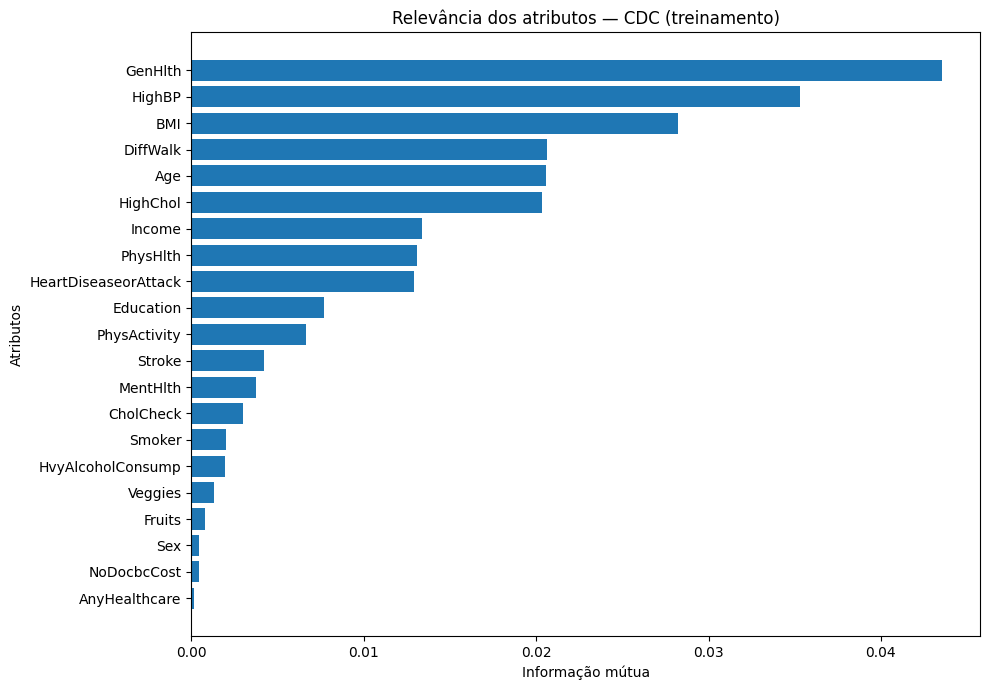

Distribuição original das classes:
0    109167
1     17673
Name: count, dtype: int64

Balanceamento aplicado.

Distribuição final das classes:
0    17673
1    17673
Name: count, dtype: int64

Conjunto: Treinamento
Quantitativos: ['BMI', 'MentHlth', 'PhysHlth']
Ordinais: ['GenHlth', 'Age', 'Education', 'Income']
Binários: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Categóricos: []


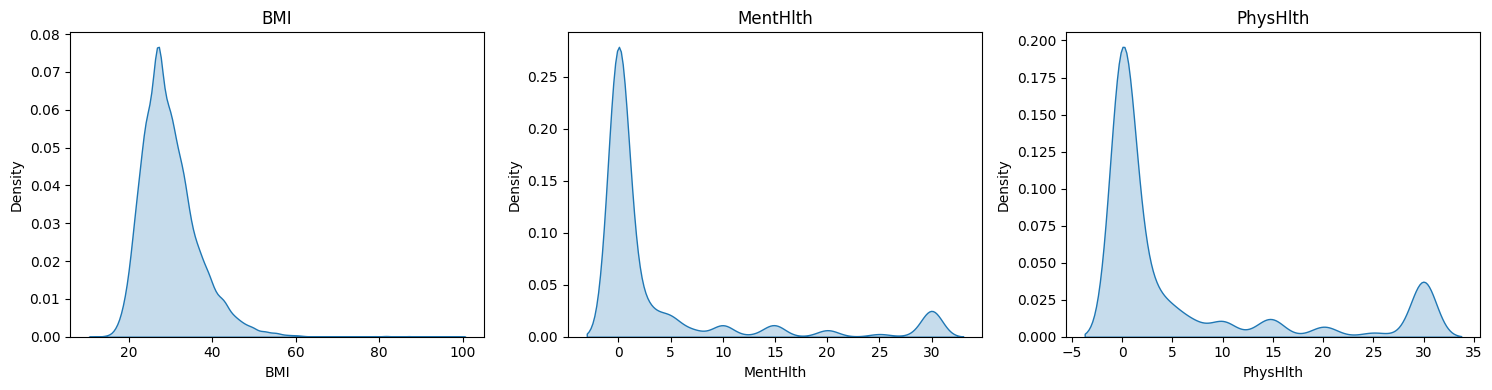

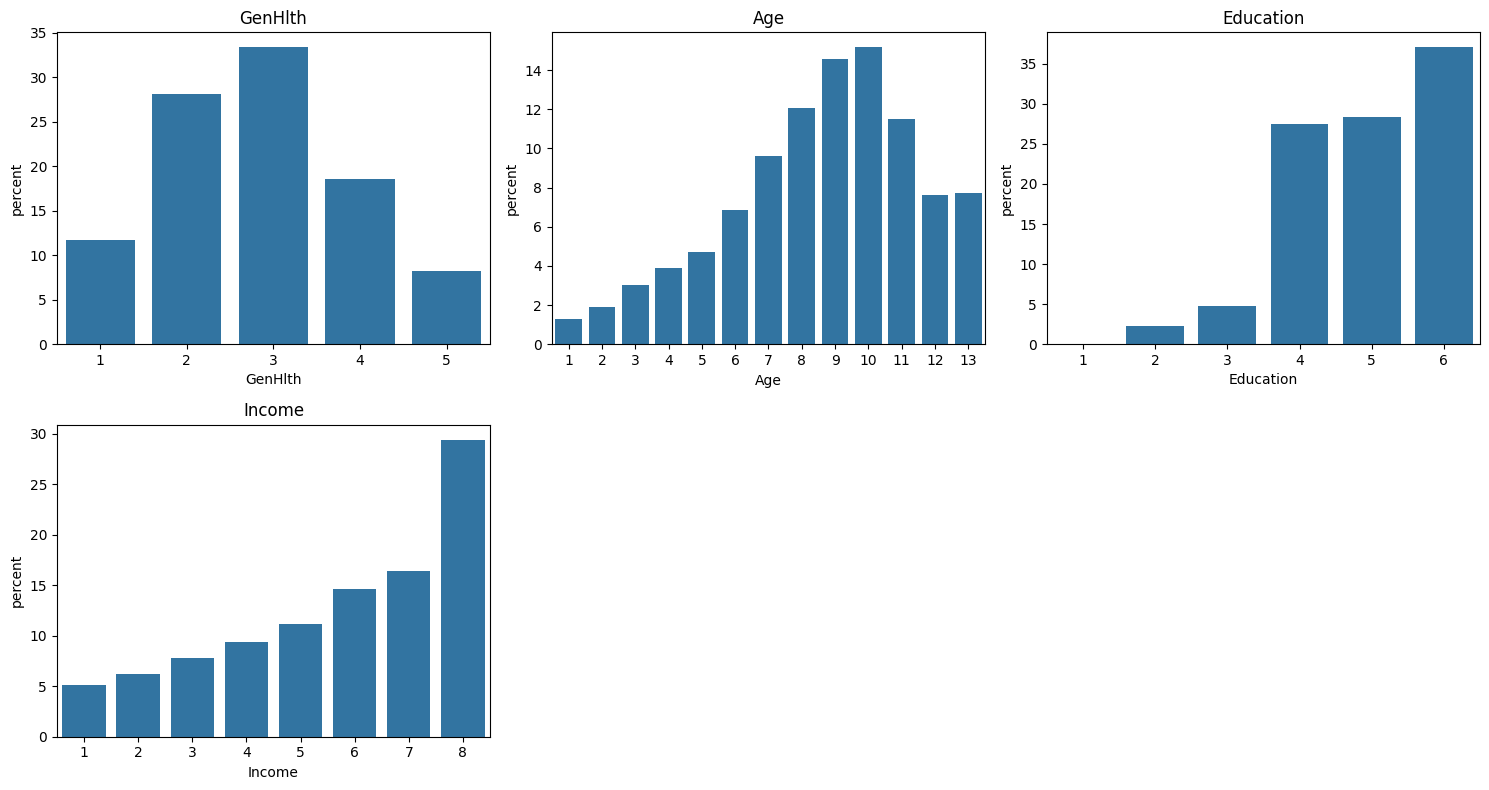

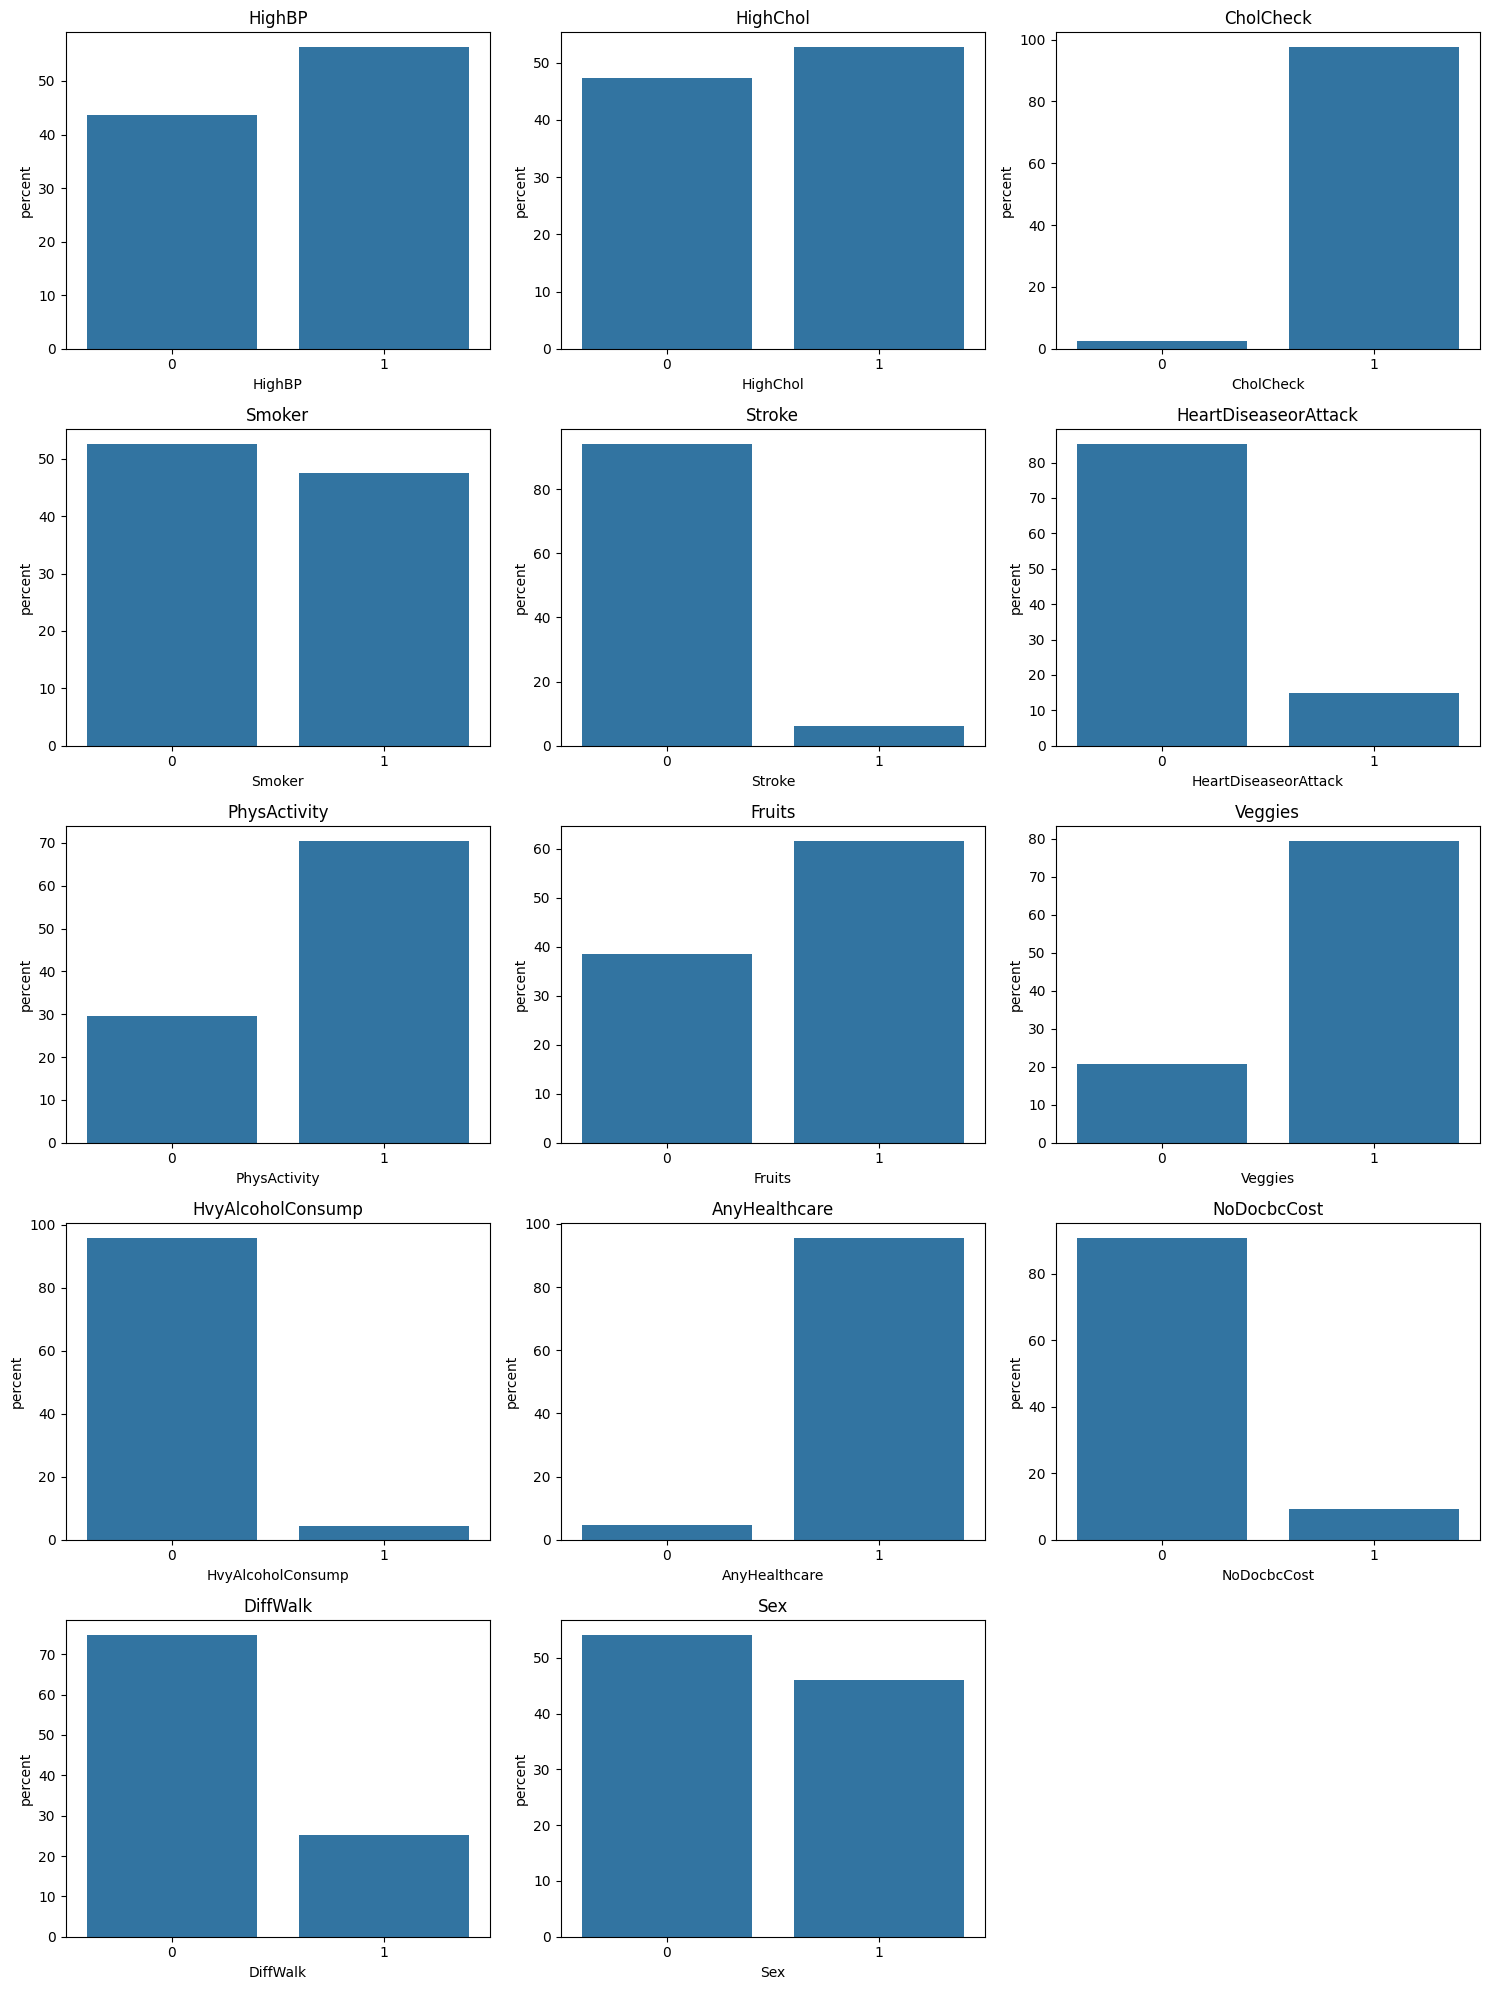

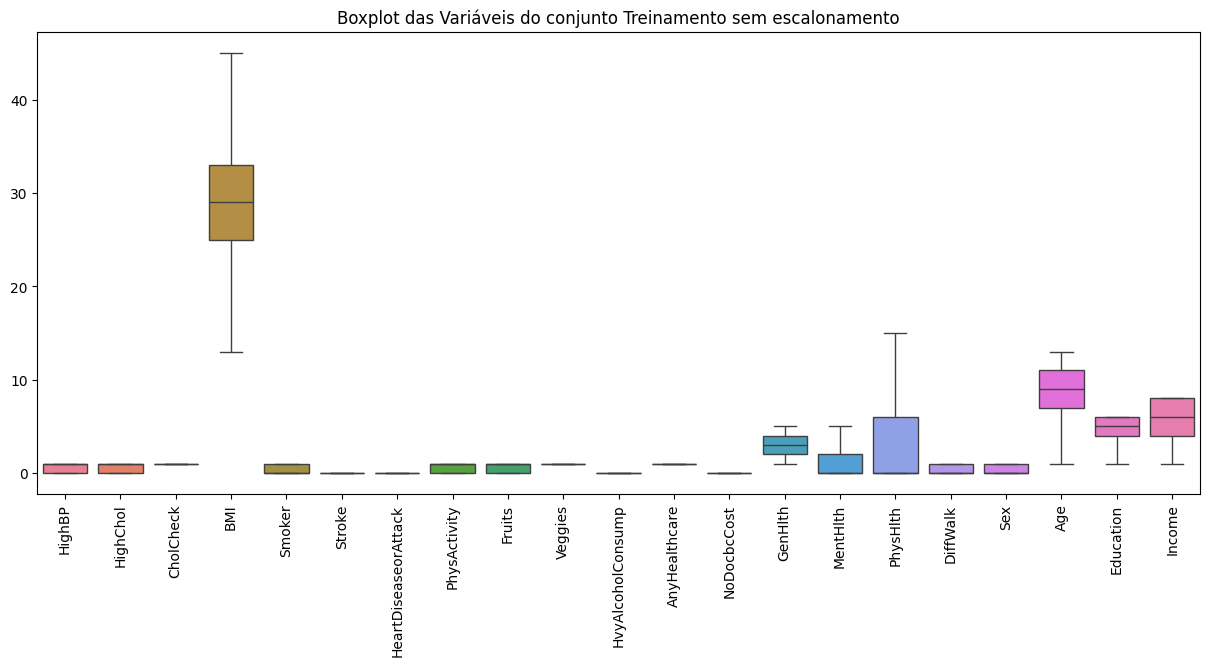

Scale ratio: 64.28
Escalas significativamente diferentes
Outlier Ratio: 4.63%
Total de Outliers: 34341
Conclusão: POUCOS outliers
Recomendação: MinMaxScaler ou StandardScaler


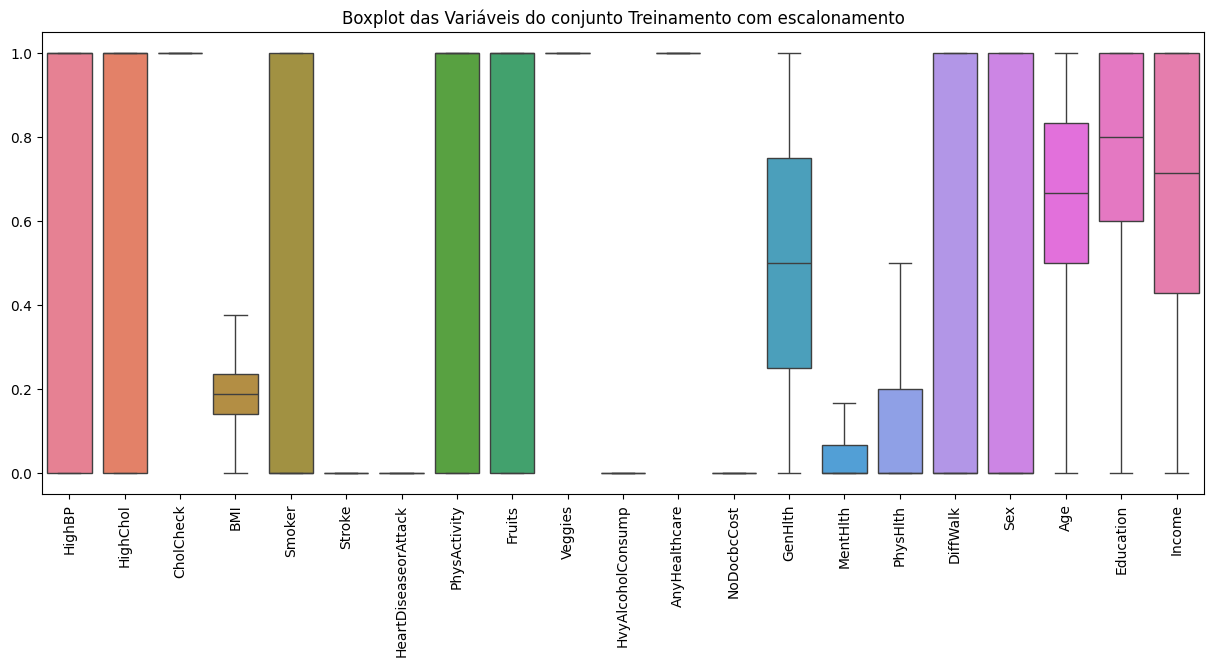

Dados do conjunto Treinamento sem escalonamento


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Classe
140480,0,0,1,23,0,0,0,1,1,1,...,0,2,0,0,0,1,12,5,5,0
89153,1,1,1,34,1,0,0,1,1,1,...,0,2,0,0,0,0,10,6,4,0
200886,1,0,1,27,0,1,0,1,1,0,...,0,2,0,0,1,1,13,4,2,0
224820,1,1,1,32,0,0,0,1,0,1,...,0,2,0,0,0,1,5,4,6,0
55691,0,0,1,25,0,0,0,1,1,0,...,0,3,0,0,0,1,4,6,8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97965,1,0,1,39,1,0,0,1,1,1,...,0,4,30,5,1,0,9,3,2,1
130895,1,1,1,35,1,0,0,0,1,0,...,0,3,0,30,0,1,11,6,7,1
149911,1,1,1,24,1,0,0,1,0,1,...,0,3,0,0,0,0,11,5,7,1
50269,1,1,1,35,1,0,0,1,0,1,...,0,2,0,0,0,1,10,4,3,1


Arquivo do conjunto Treinamento sem escalonamento salvo com sucesso!

Dados do conjunto Treinamento com escalonamento


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Classe
140480,0.0,0.0,1.0,0.117647,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.25,0.0,0.000000,0.0,1.0,0.916667,0.8,0.571429,0
89153,1.0,1.0,1.0,0.247059,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.25,0.0,0.000000,0.0,0.0,0.750000,1.0,0.428571,0
200886,1.0,0.0,1.0,0.164706,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.25,0.0,0.000000,1.0,1.0,1.000000,0.6,0.142857,0
224820,1.0,1.0,1.0,0.223529,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.25,0.0,0.000000,0.0,1.0,0.333333,0.6,0.714286,0
55691,0.0,0.0,1.0,0.141176,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.50,0.0,0.000000,0.0,1.0,0.250000,1.0,1.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97965,1.0,0.0,1.0,0.305882,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.75,1.0,0.166667,1.0,0.0,0.666667,0.4,0.142857,1
130895,1.0,1.0,1.0,0.258824,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.50,0.0,1.000000,0.0,1.0,0.833333,1.0,0.857143,1
149911,1.0,1.0,1.0,0.129412,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.50,0.0,0.000000,0.0,0.0,0.833333,0.8,0.857143,1
50269,1.0,1.0,1.0,0.258824,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.25,0.0,0.000000,0.0,1.0,0.750000,0.6,0.285714,1


Arquivo do conjunto Treinamento com escalonamento salvo com sucesso!


Conjunto: Teste
Quantitativos: ['BMI', 'MentHlth', 'PhysHlth']
Ordinais: ['GenHlth', 'Age', 'Education', 'Income']
Binários: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Categóricos: []


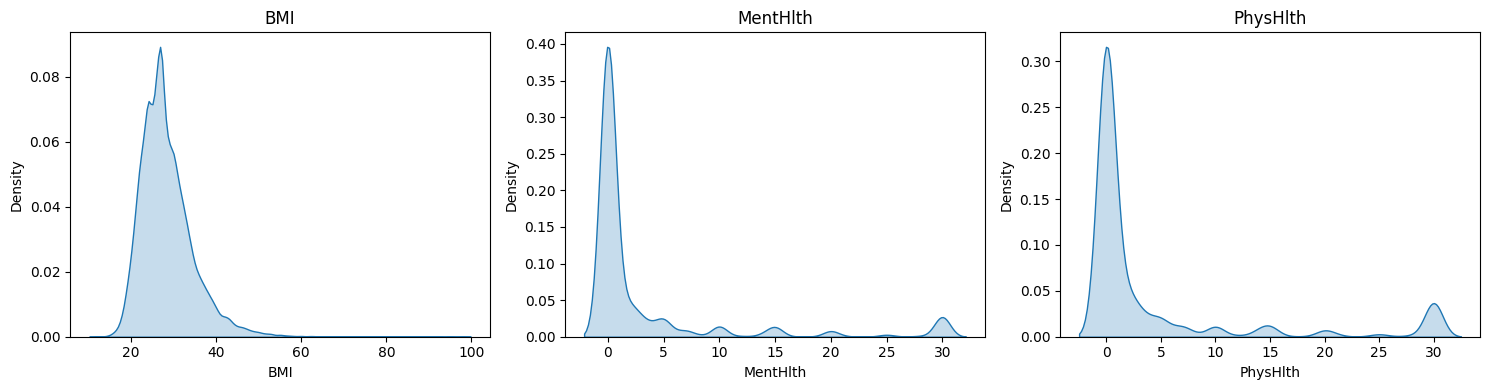

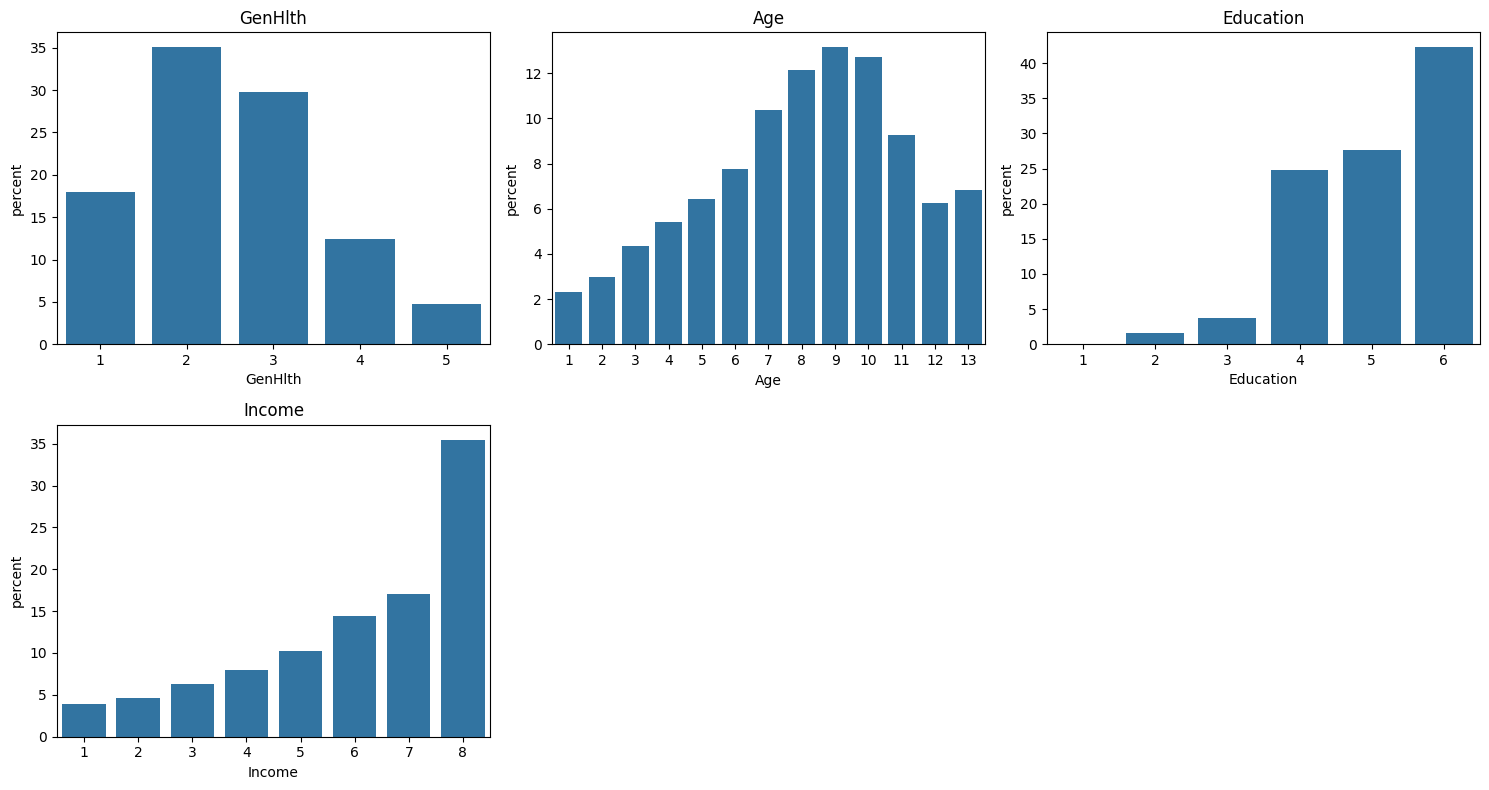

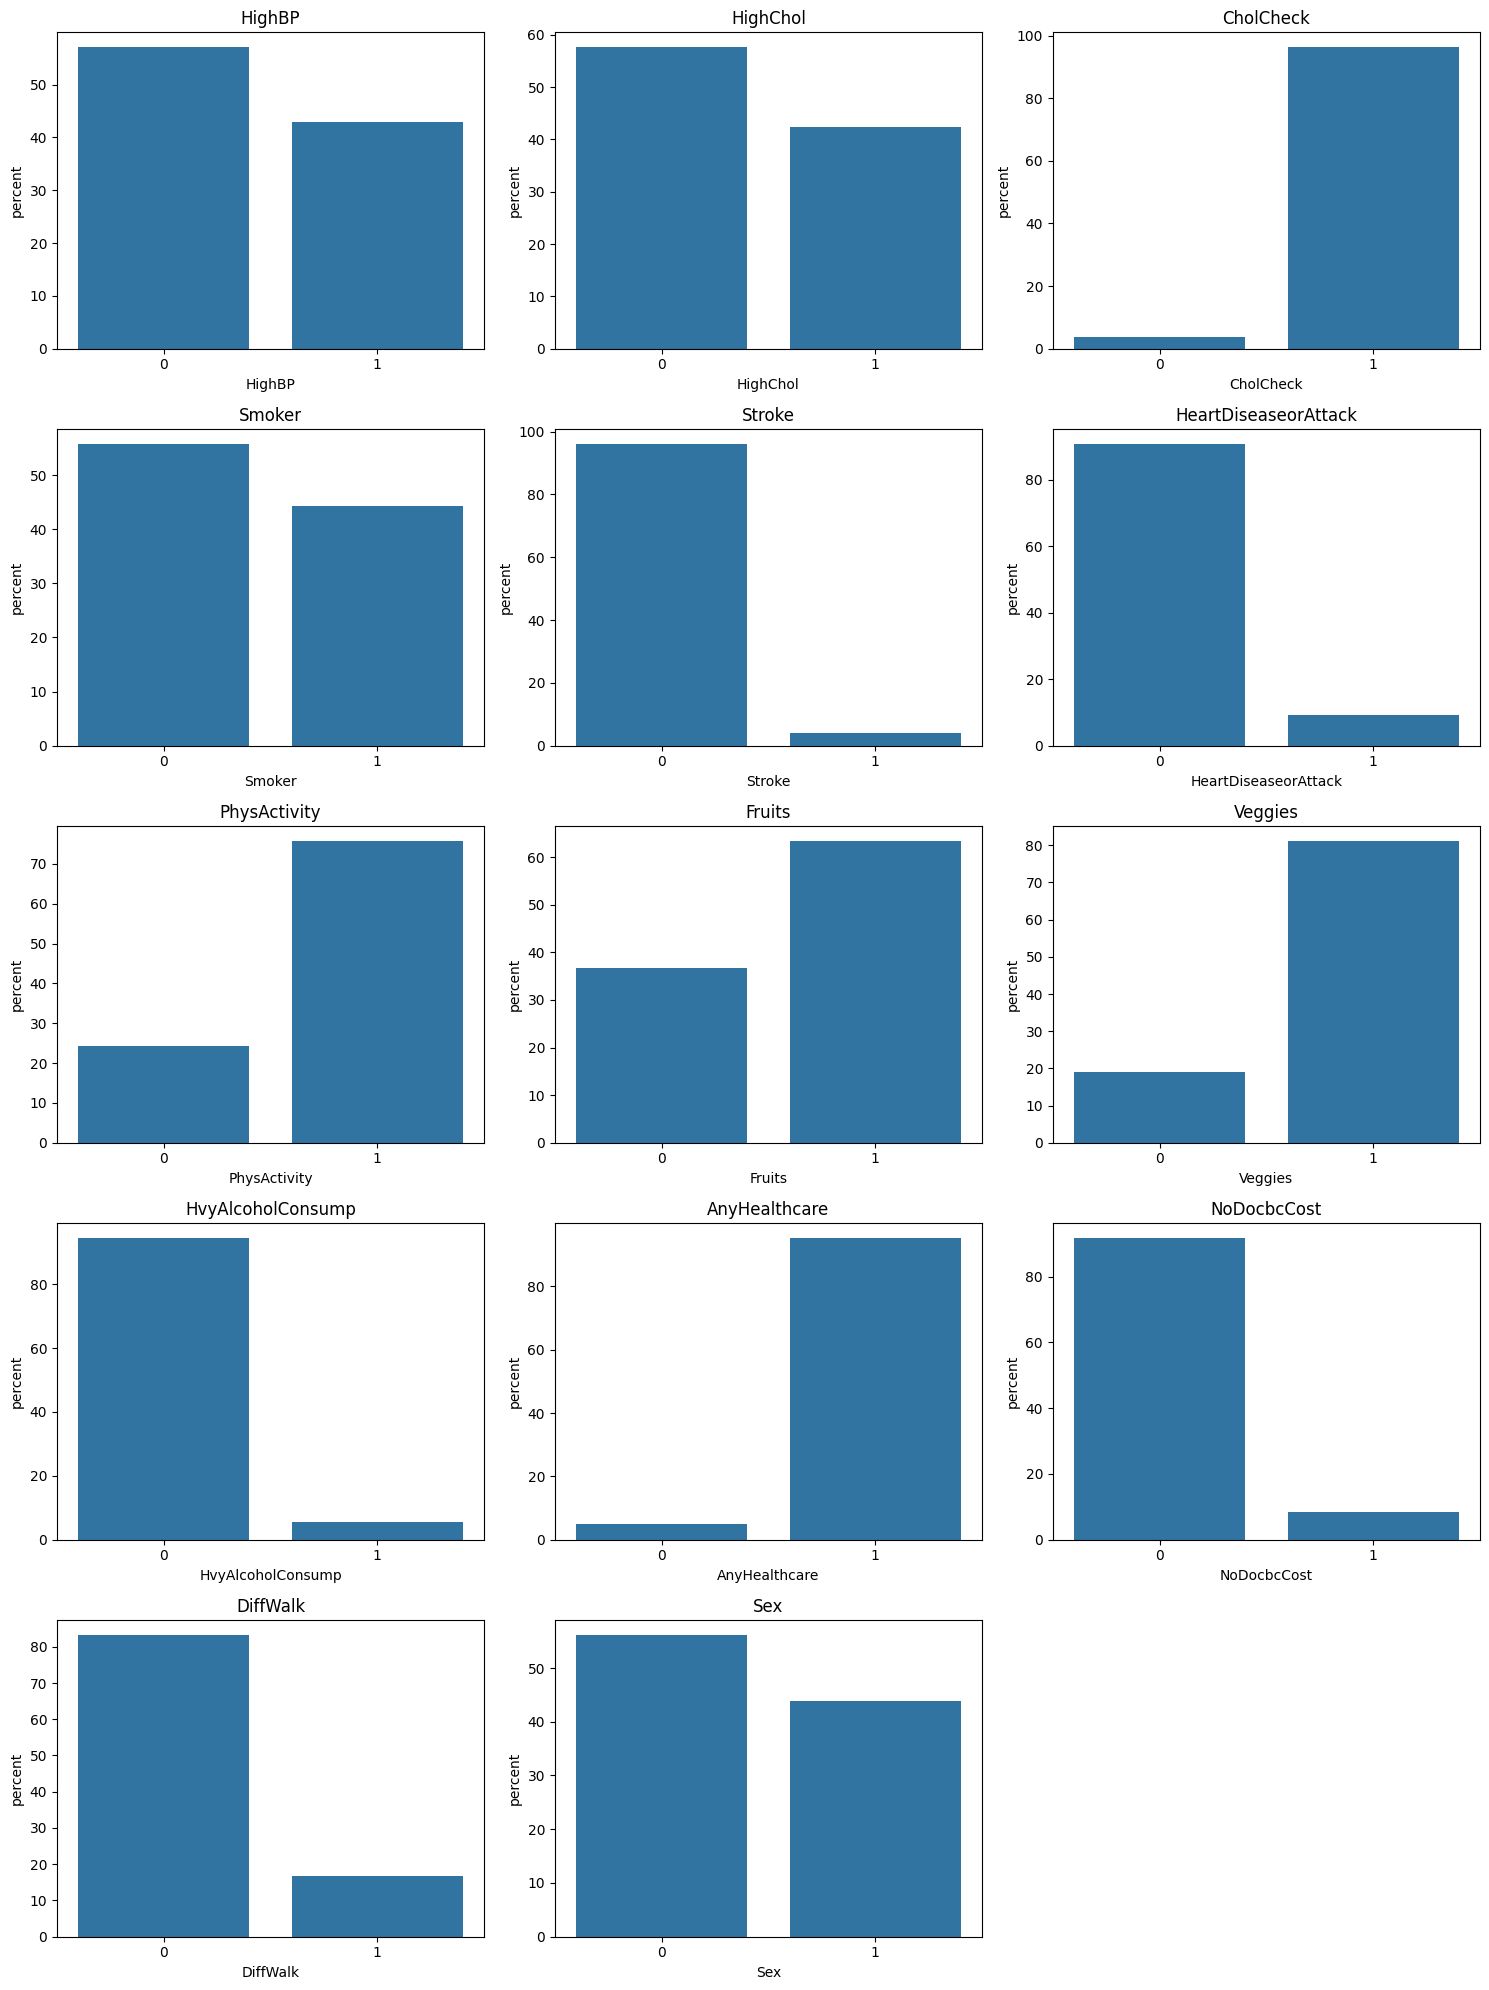

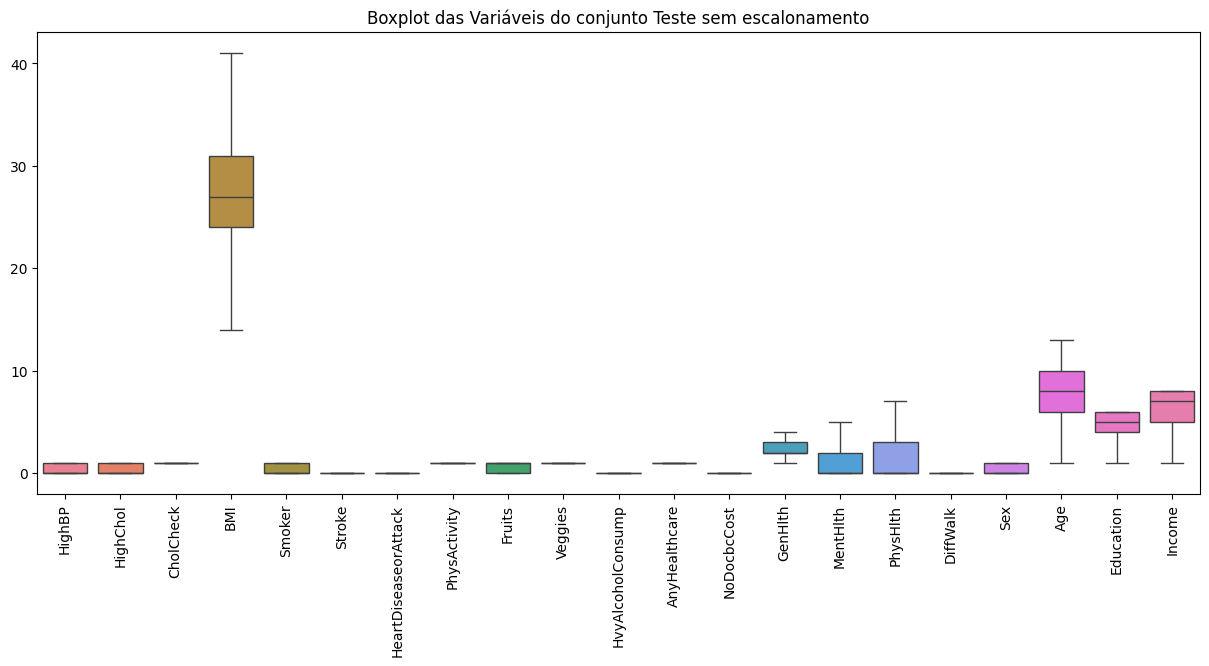

Aplicando escalonador padrão: MinMaxScaler


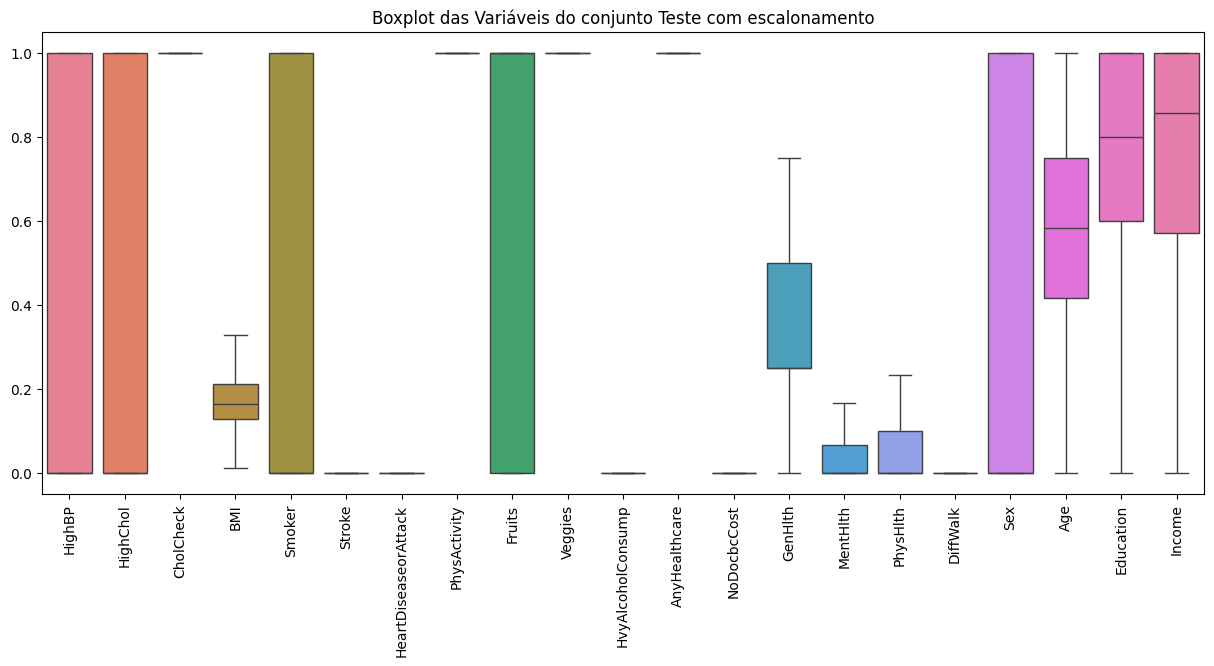

Dados do conjunto Teste sem escalonamento


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Classe
21357,0,0,1,31,1,0,0,1,0,1,...,0,3,0,0,0,1,9,4,6,1
240070,0,0,1,26,0,0,0,1,1,1,...,0,1,0,0,0,1,8,6,7,0
32248,1,0,1,39,1,0,1,0,1,1,...,0,5,25,15,1,0,7,4,1,0
154948,1,1,1,25,0,0,0,0,0,1,...,0,3,0,5,1,0,13,4,2,1
99261,0,0,1,25,0,0,0,1,0,0,...,0,2,14,2,0,0,5,5,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233386,0,1,1,24,1,0,0,1,1,1,...,0,2,2,2,0,1,9,5,7,0
106479,1,1,1,34,1,0,1,0,0,0,...,1,5,10,30,1,1,12,5,4,1
30612,0,1,0,19,1,0,0,1,1,1,...,0,1,0,0,0,0,10,5,6,0
215202,1,1,1,50,0,0,0,1,1,1,...,0,4,0,0,0,0,7,4,6,1


Arquivo do conjunto Teste sem escalonamento salvo com sucesso!

Dados do conjunto Teste com escalonamento


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Classe
21357,0.0,0.0,1.0,0.211765,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.50,0.000000,0.000000,0.0,1.0,0.666667,0.6,0.714286,1
240070,0.0,0.0,1.0,0.152941,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.00,0.000000,0.000000,0.0,1.0,0.583333,1.0,0.857143,0
32248,1.0,0.0,1.0,0.305882,1.0,0.0,1.0,0.0,1.0,1.0,...,0.0,1.00,0.833333,0.500000,1.0,0.0,0.500000,0.6,0.000000,0
154948,1.0,1.0,1.0,0.141176,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.50,0.000000,0.166667,1.0,0.0,1.000000,0.6,0.142857,1
99261,0.0,0.0,1.0,0.141176,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.25,0.466667,0.066667,0.0,0.0,0.333333,0.8,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233386,0.0,1.0,1.0,0.129412,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.25,0.066667,0.066667,0.0,1.0,0.666667,0.8,0.857143,0
106479,1.0,1.0,1.0,0.247059,1.0,0.0,1.0,0.0,0.0,0.0,...,1.0,1.00,0.333333,1.000000,1.0,1.0,0.916667,0.8,0.428571,1
30612,0.0,1.0,0.0,0.070588,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.00,0.000000,0.000000,0.0,0.0,0.750000,0.8,0.714286,0
215202,1.0,1.0,1.0,0.435294,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.75,0.000000,0.000000,0.0,0.0,0.500000,0.6,0.714286,1


Arquivo do conjunto Teste com escalonamento salvo com sucesso!


Conjunto: Treinamento_Completo
Quantitativos: ['BMI', 'MentHlth', 'PhysHlth']
Ordinais: ['GenHlth', 'Age', 'Education', 'Income']
Binários: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Categóricos: []


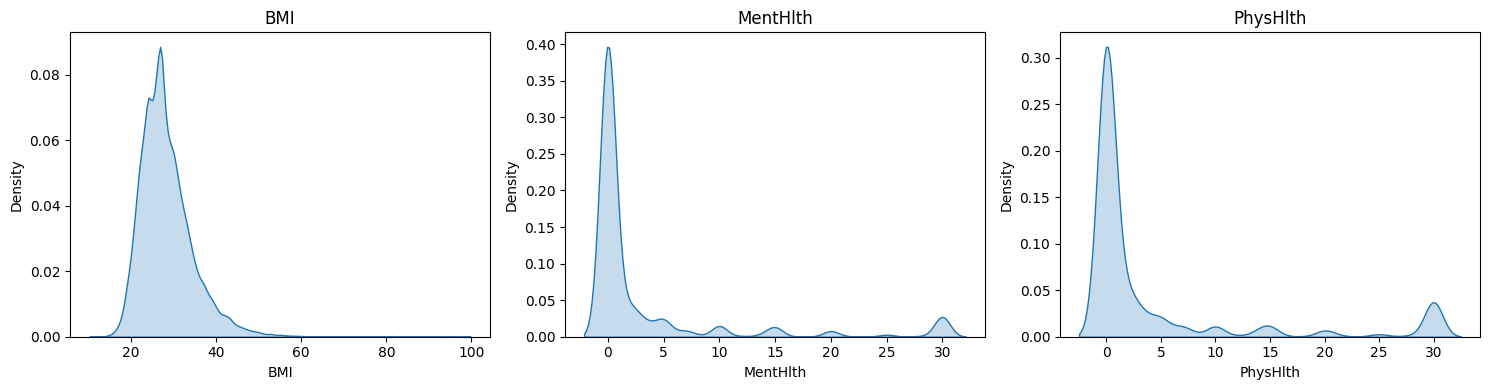

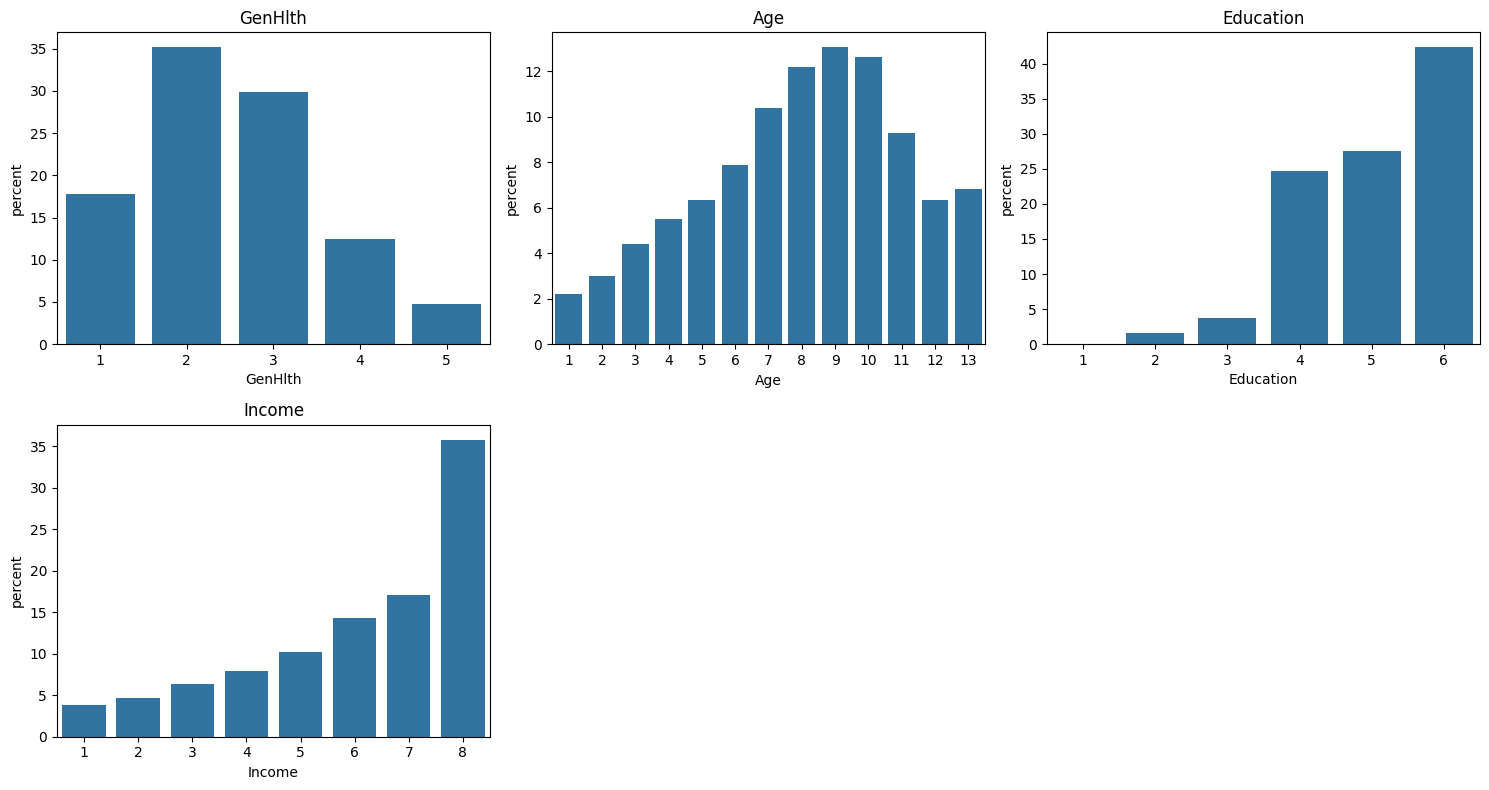

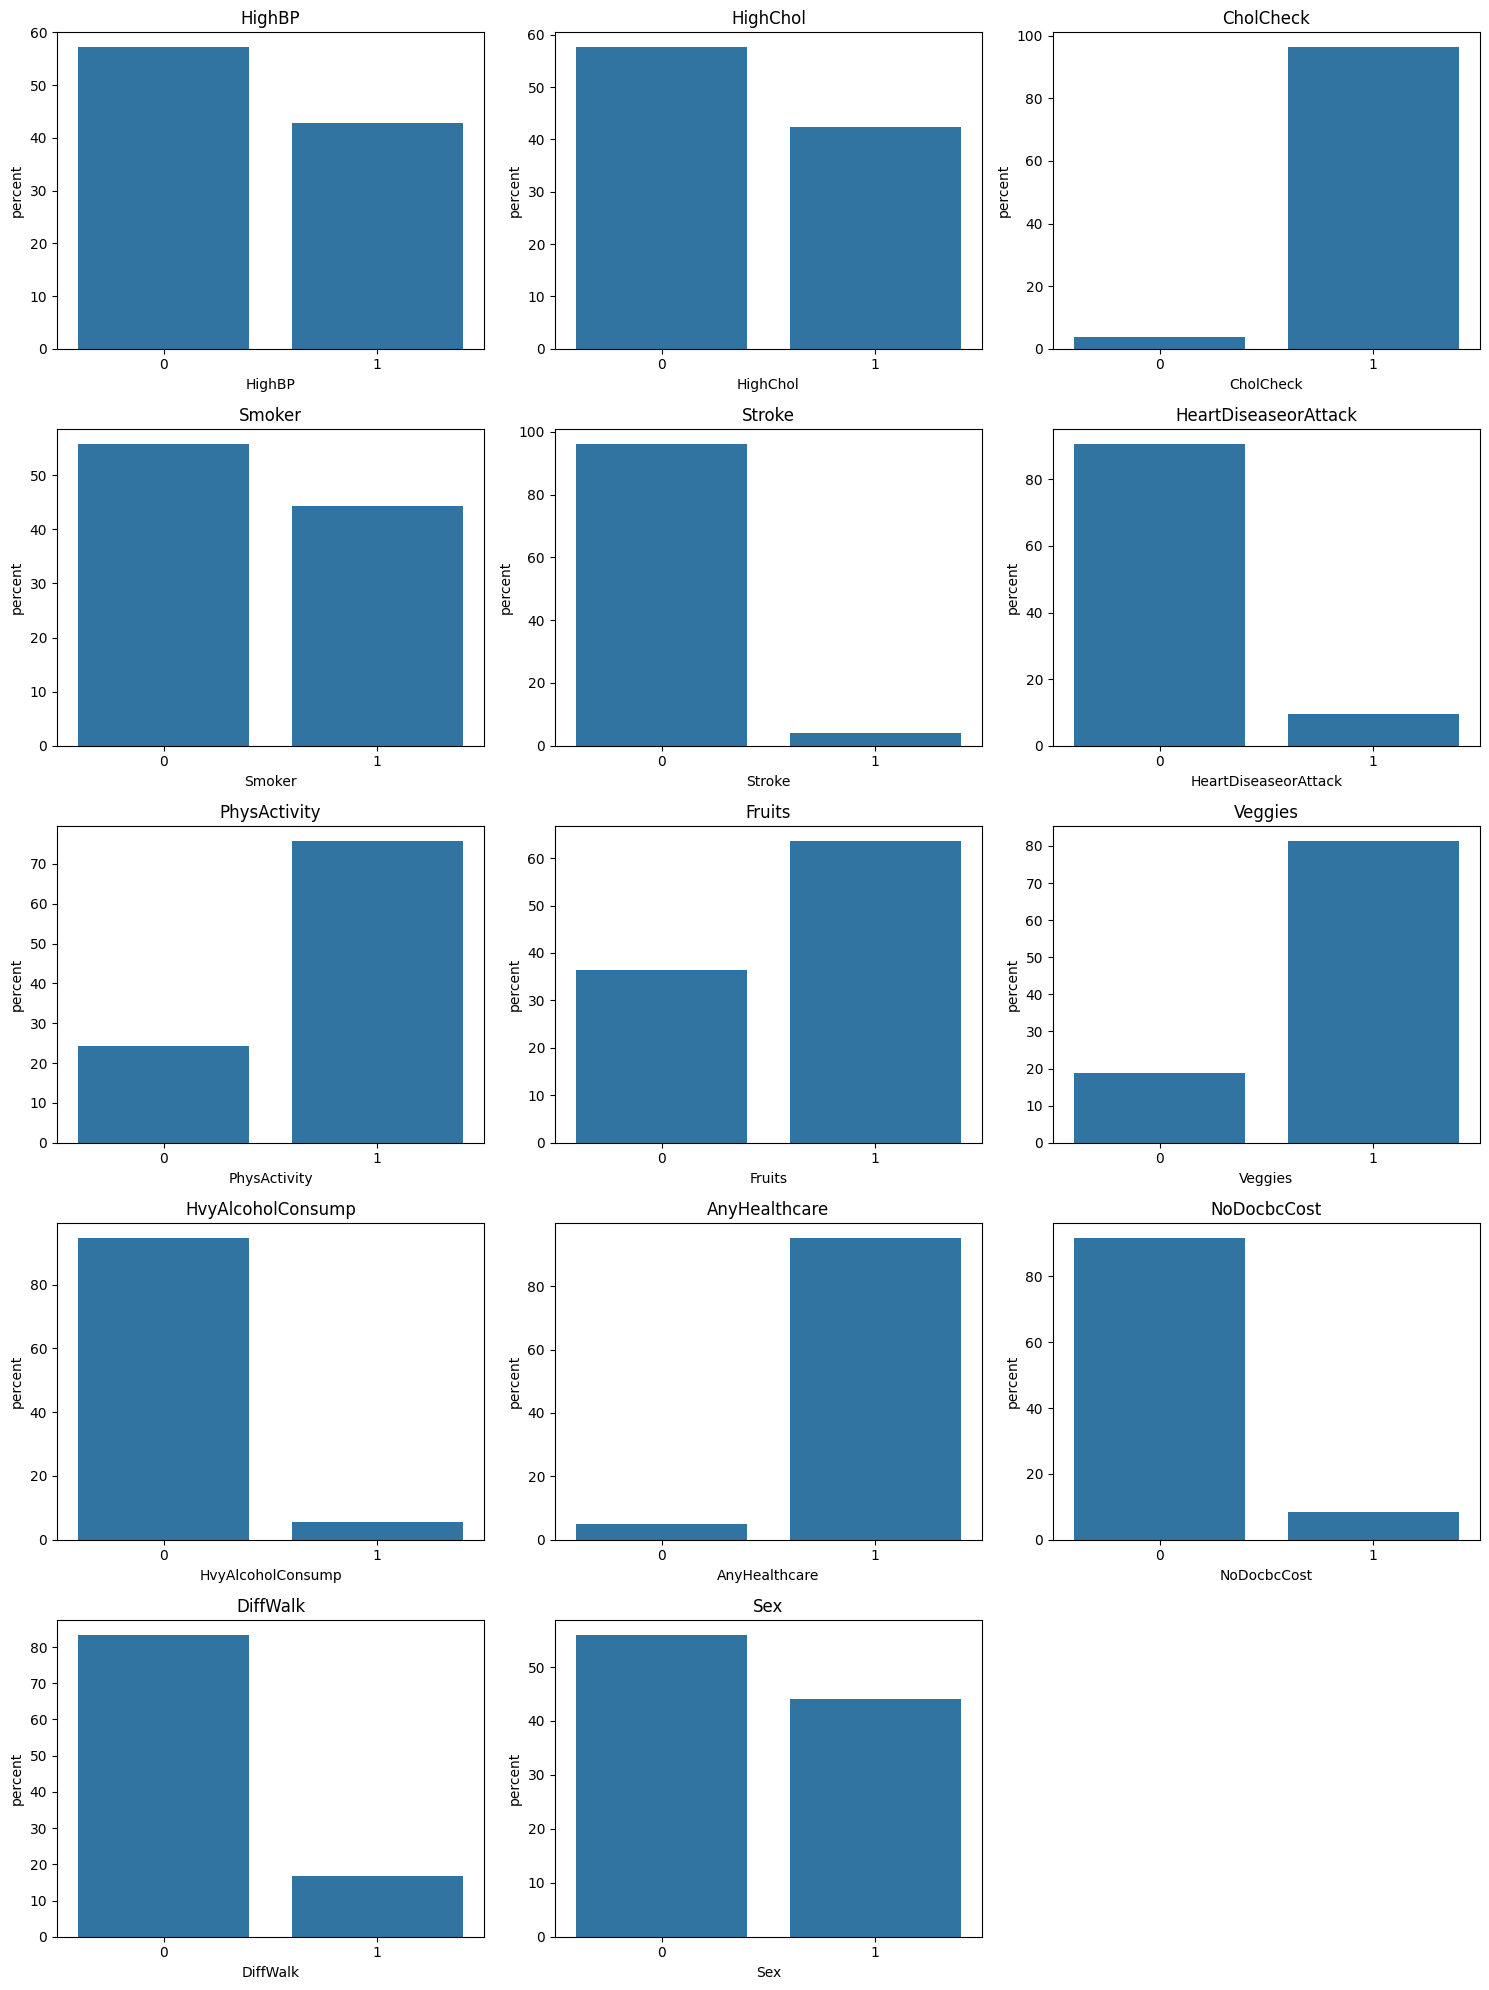

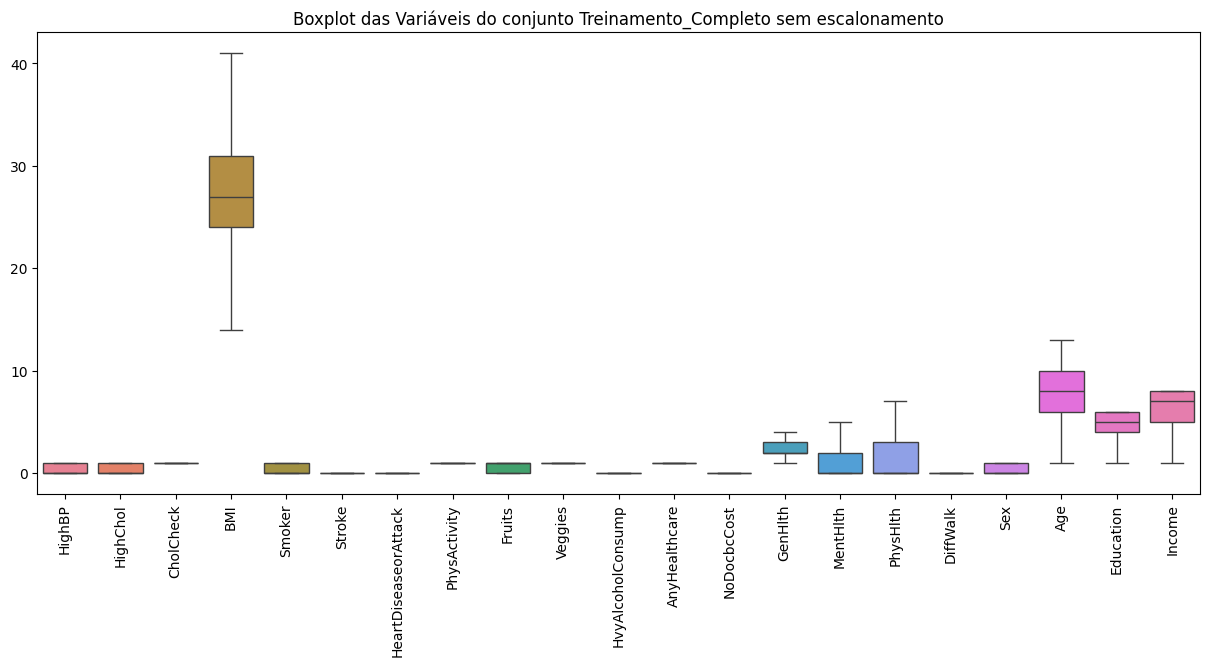

Aplicando escalonador padrão: MinMaxScaler


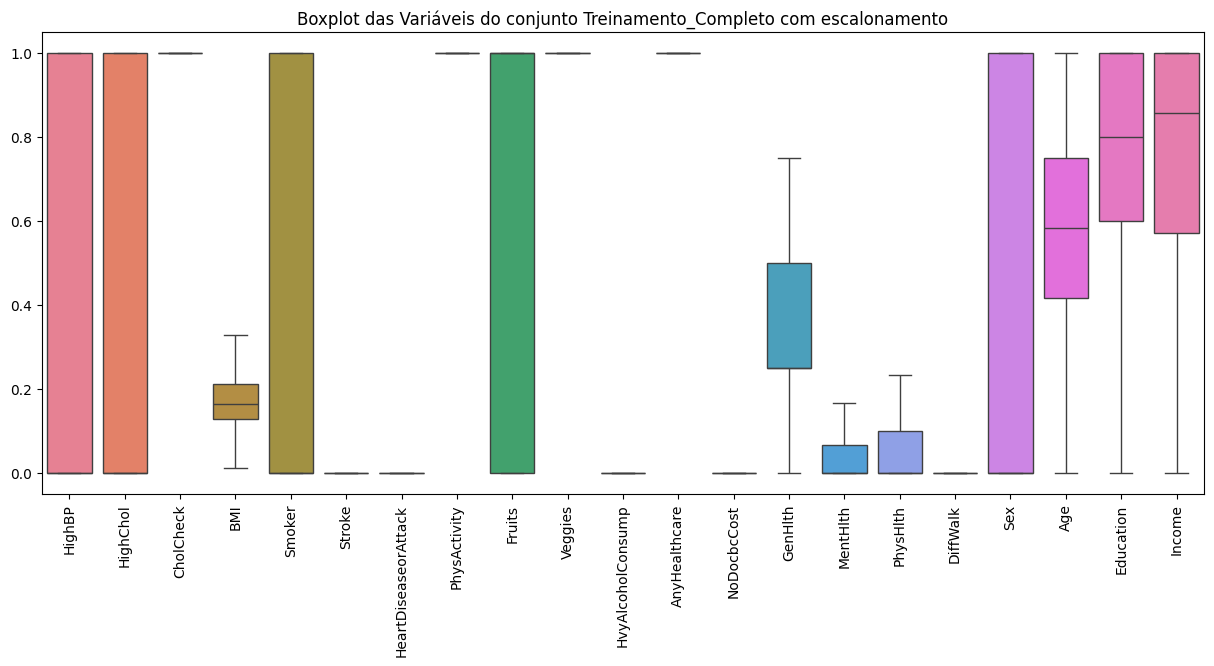

Dados do conjunto Treinamento_Completo sem escalonamento


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Classe
134153,0,0,1,34,1,0,1,1,0,0,...,0,3,7,5,0,1,9,6,5,0
6491,1,1,1,29,0,0,0,0,1,1,...,0,1,0,0,0,0,8,6,8,0
235460,0,1,1,27,0,0,0,1,1,1,...,0,2,0,0,0,1,7,6,8,0
201348,0,0,1,19,1,0,0,1,1,1,...,0,2,0,0,0,1,1,5,3,0
150355,0,0,1,24,1,0,0,1,1,1,...,0,1,30,3,0,0,6,5,8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110473,0,1,1,31,1,0,0,1,1,1,...,0,2,0,0,0,0,6,6,8,0
34329,0,1,1,24,0,0,0,1,1,1,...,1,3,30,0,0,1,7,6,7,0
238708,1,1,1,36,0,0,1,0,0,0,...,0,5,0,12,1,0,8,6,3,1
169342,1,0,1,24,1,0,0,1,0,1,...,0,1,0,0,0,0,10,4,6,0


Arquivo do conjunto Treinamento_Completo sem escalonamento salvo com sucesso!

Dados do conjunto Treinamento_Completo com escalonamento


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Classe
134153,0.0,0.0,1.0,0.247059,1.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.50,0.233333,0.166667,0.0,1.0,0.666667,1.0,0.571429,0
6491,1.0,1.0,1.0,0.188235,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.00,0.000000,0.000000,0.0,0.0,0.583333,1.0,1.000000,0
235460,0.0,1.0,1.0,0.164706,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.25,0.000000,0.000000,0.0,1.0,0.500000,1.0,1.000000,0
201348,0.0,0.0,1.0,0.070588,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.25,0.000000,0.000000,0.0,1.0,0.000000,0.8,0.285714,0
150355,0.0,0.0,1.0,0.129412,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.00,1.000000,0.100000,0.0,0.0,0.416667,0.8,1.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110473,0.0,1.0,1.0,0.211765,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.25,0.000000,0.000000,0.0,0.0,0.416667,1.0,1.000000,0
34329,0.0,1.0,1.0,0.129412,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.50,1.000000,0.000000,0.0,1.0,0.500000,1.0,0.857143,0
238708,1.0,1.0,1.0,0.270588,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.00,0.000000,0.400000,1.0,0.0,0.583333,1.0,0.285714,1
169342,1.0,0.0,1.0,0.129412,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.00,0.000000,0.000000,0.0,0.0,0.750000,0.6,0.714286,0


Arquivo do conjunto Treinamento_Completo com escalonamento salvo com sucesso!


Conjunto: Completo
Quantitativos: ['BMI', 'MentHlth', 'PhysHlth']
Ordinais: ['GenHlth', 'Age', 'Education', 'Income']
Binários: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Categóricos: []


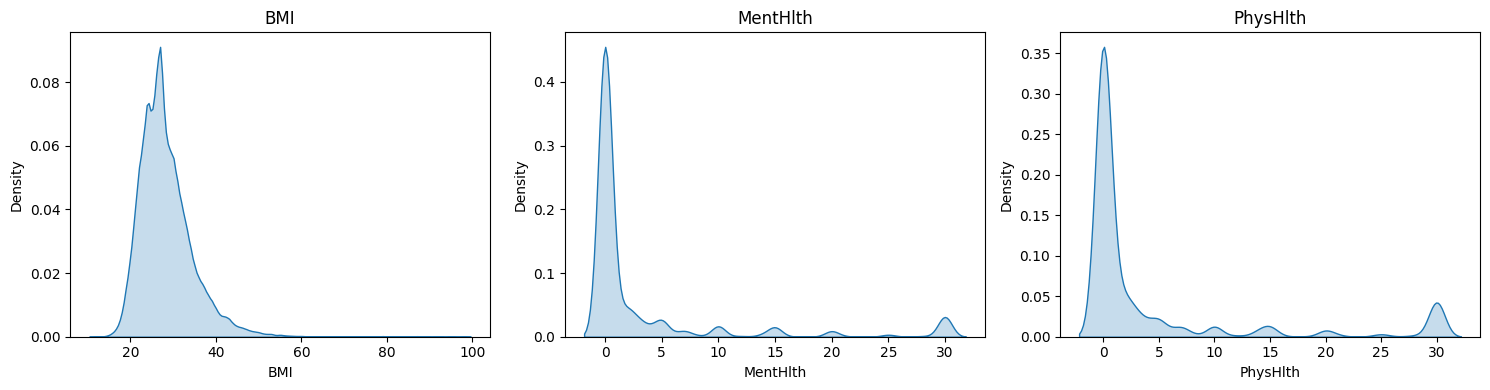

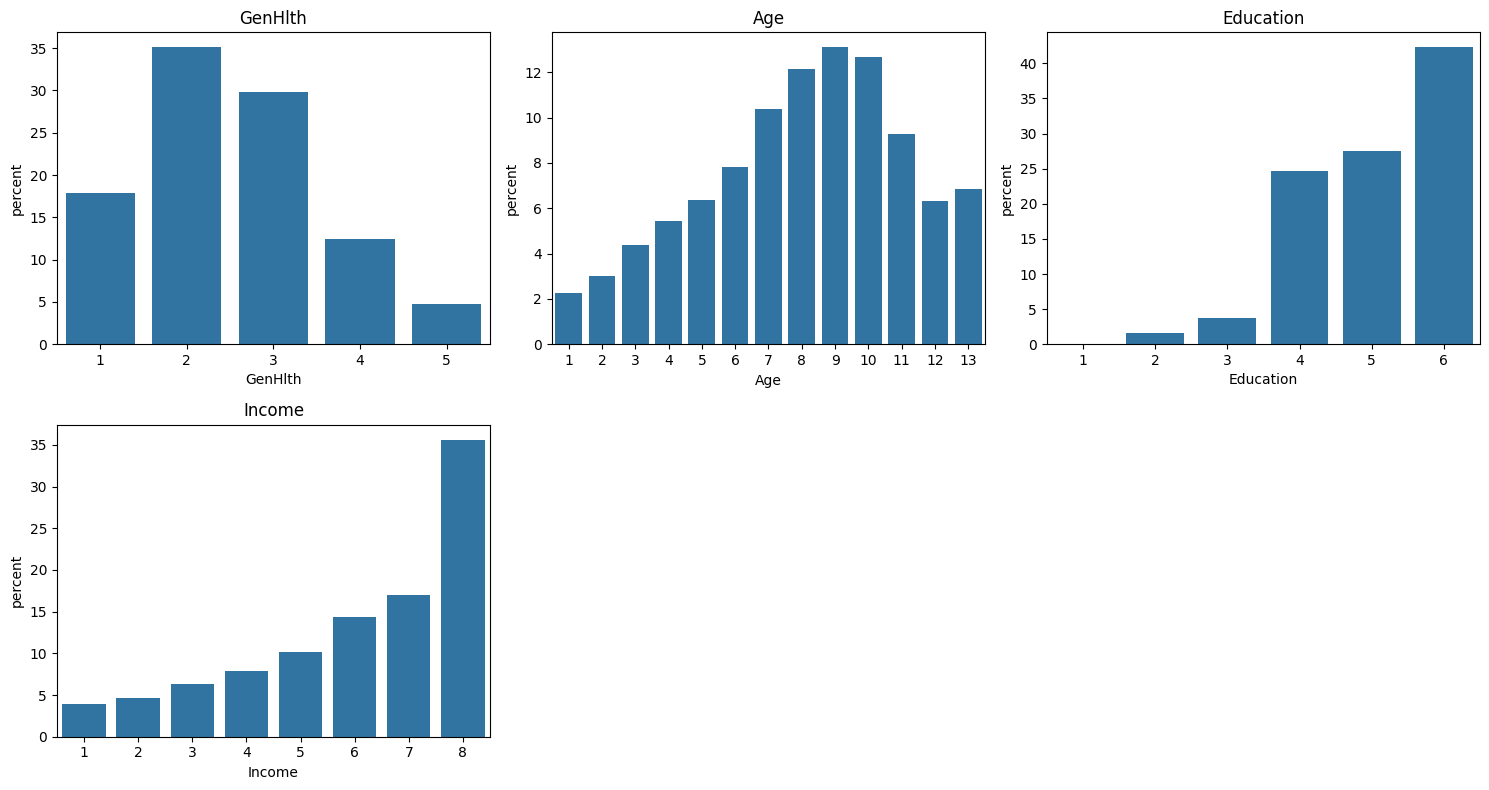

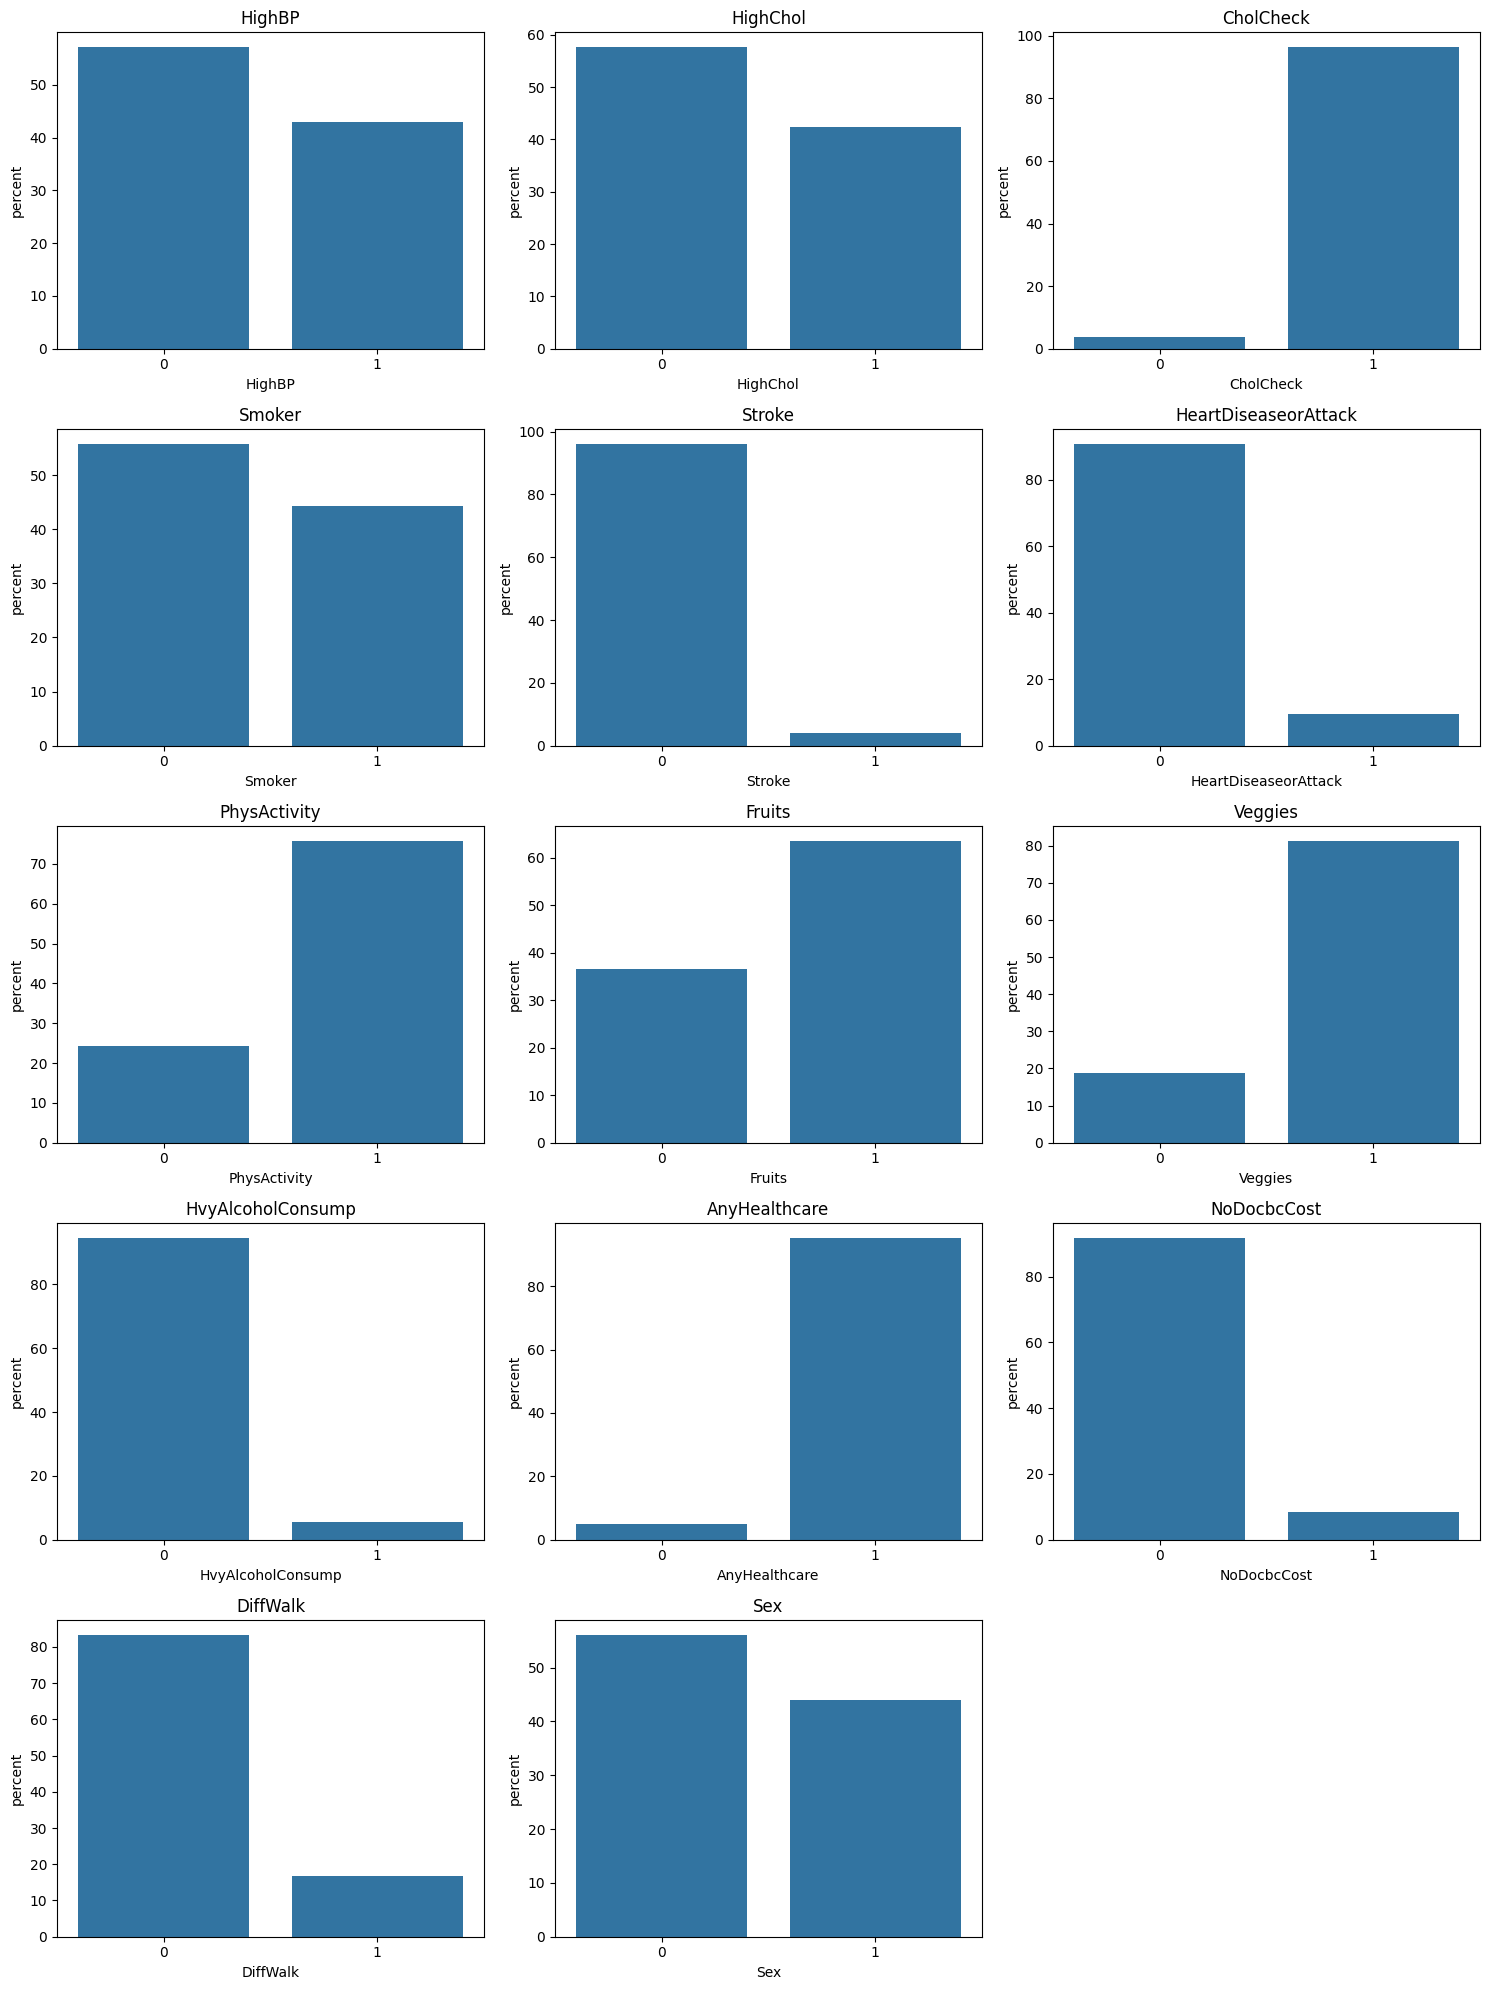

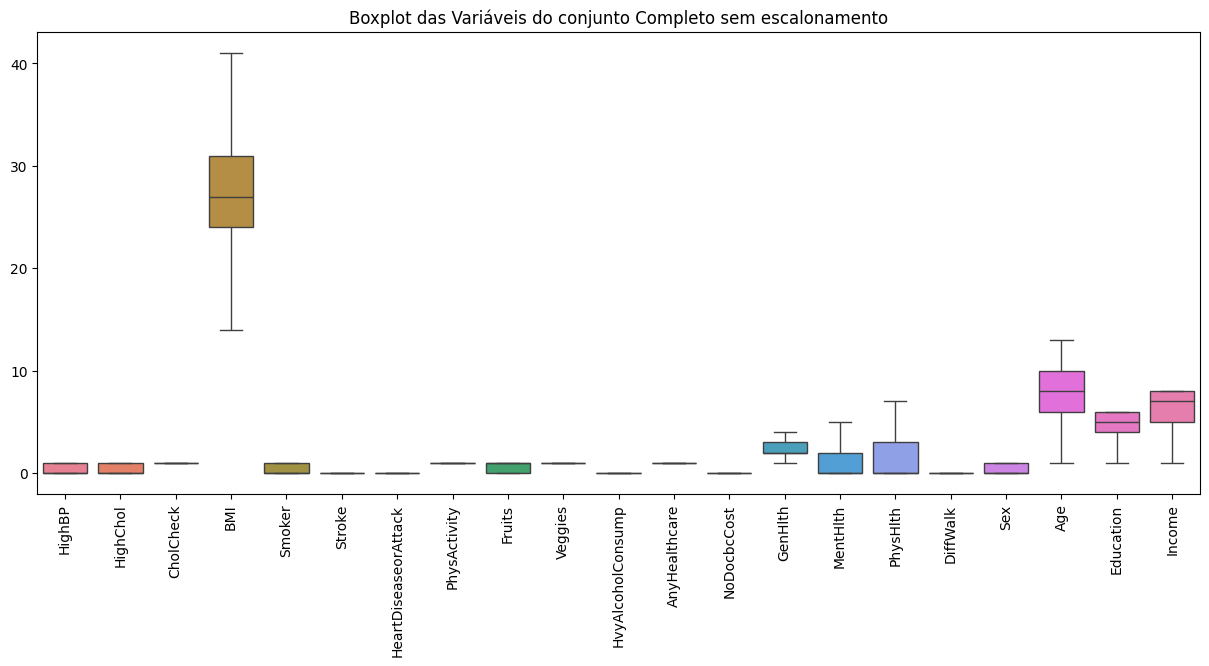

Aplicando escalonador padrão: MinMaxScaler


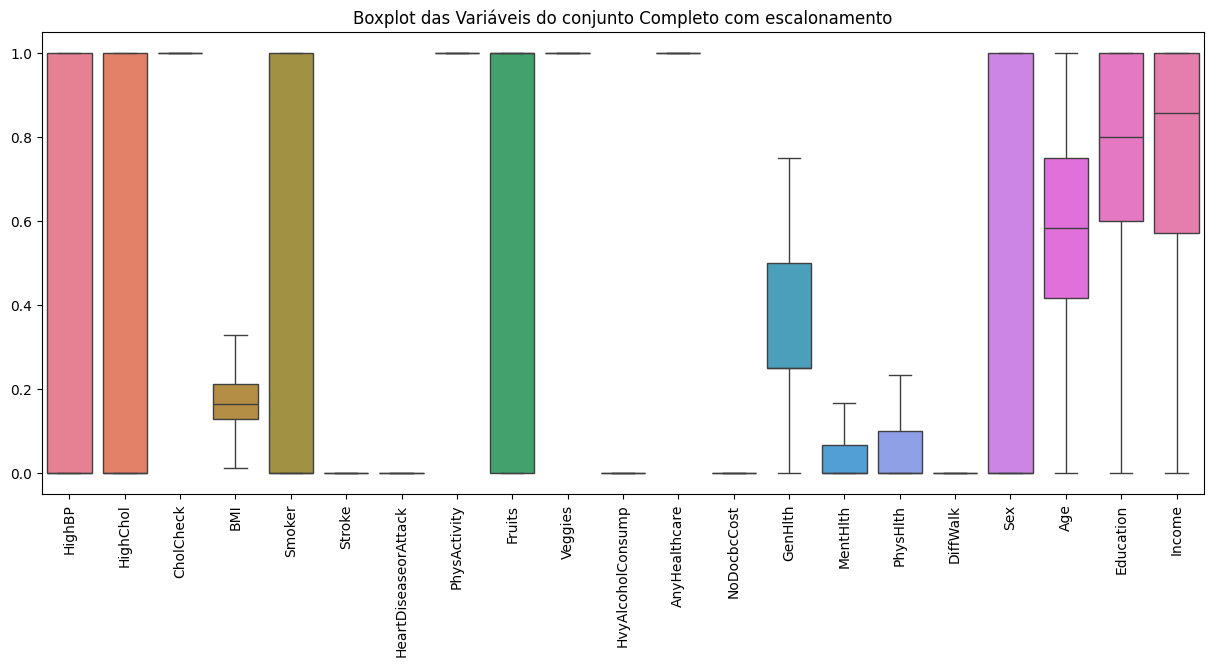

Dados do conjunto Completo sem escalonamento


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Classe
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
253675,1,1,1,45,0,0,0,0,1,1,...,0,3,0,5,0,1,5,6,7,0
253676,1,1,1,18,0,0,0,0,0,0,...,0,4,0,0,1,0,11,2,4,1
253677,0,0,1,28,0,0,0,1,1,0,...,0,1,0,0,0,0,2,5,2,0
253678,1,0,1,23,0,0,0,0,1,1,...,0,3,0,0,0,1,7,5,1,0


Arquivo do conjunto Completo sem escalonamento salvo com sucesso!

Dados do conjunto Completo com escalonamento


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Classe
0,1.0,1.0,1.0,0.317647,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.00,0.6,0.500000,1.0,0.0,0.666667,0.6,0.285714,0
1,0.0,0.0,0.0,0.141176,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.50,0.0,0.000000,0.0,0.0,0.500000,1.0,0.000000,0
2,1.0,1.0,1.0,0.176471,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,1.00,1.0,1.000000,1.0,0.0,0.666667,0.6,1.000000,0
3,1.0,0.0,1.0,0.164706,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.25,0.0,0.000000,0.0,0.0,0.833333,0.4,0.714286,0
4,1.0,1.0,1.0,0.129412,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.25,0.1,0.000000,0.0,0.0,0.833333,0.8,0.428571,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
253675,1.0,1.0,1.0,0.376471,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.50,0.0,0.166667,0.0,1.0,0.333333,1.0,0.857143,0
253676,1.0,1.0,1.0,0.058824,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.75,0.0,0.000000,1.0,0.0,0.833333,0.2,0.428571,1
253677,0.0,0.0,1.0,0.176471,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.00,0.0,0.000000,0.0,0.0,0.083333,0.8,0.142857,0
253678,1.0,0.0,1.0,0.117647,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.50,0.0,0.000000,0.0,1.0,0.500000,0.8,0.000000,0


Arquivo do conjunto Completo com escalonamento salvo com sucesso!



In [ ]:
#===============================================
# Separa treinamento e teste
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.50,
    stratify=Y,
    random_state=42
)

X_train_completo = X_train
Y_train_completo = Y_train

print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

#===============================================
# Calcula informação mútua somente no treinamento, antes do balanceamento

# Prepara os dados
X_train_mi = X_train.copy()

# Identifica automaticamente os atributos discretos
discretos_mi = [
    pd.api.types.is_bool_dtype(X_train_mi[col])
    or (
        X_train_mi[col].nunique() <= 15
        and np.all(
            X_train_mi[col].dropna() % 1 == 0
        )
    )
    for col in X_train_mi.columns
]

# Calcula informação mútua
mi = mutual_info_classif(
    X_train_mi.astype(float),
    Y_train,
    discrete_features=discretos_mi,
    random_state=42
)

# Organiza a relevância dos atributos
relevancia = pd.DataFrame({
    "Atributo": X_train_mi.columns,
    "Informacao_mutua": mi,
    "Tipo": [
        "Discreto" if d else "Contínuo"
        for d in discretos_mi
    ]
}).sort_values(
    by="Informacao_mutua",
    ascending=False
)

display(relevancia)

# Visualiza a relevância
plt.figure(figsize=(10, 7))

plt.barh(
    relevancia["Atributo"],
    relevancia["Informacao_mutua"]
)

plt.gca().invert_yaxis()
plt.xlabel("Informação mútua")
plt.ylabel("Atributos")
plt.title(f"Relevância dos atributos — {base_name} (treinamento)")
plt.tight_layout()
plt.show()

#===============================================
# Balanceamento automático do conjunto de treinamento

# Distribuição original das classes
distribuicao = pd.Series(Y_train).value_counts()

print("Distribuição original das classes:")
print(distribuicao.sort_index())

# Calcula a proporção entre a classe minoritária e a majoritária
proporcao = distribuicao.min() / distribuicao.max()

# Define o limite para aplicar balanceamento
limite_balanceamento = 0.5

if proporcao < limite_balanceamento:

    # Reduz a classe majoritária para uma proporção de 1:1
    balanceador = RandomUnderSampler(
        sampling_strategy=1.0,
        random_state=42
    )

    X_train_bal, Y_train_bal = balanceador.fit_resample(
        X_train,
        Y_train
    )

    print("\nBalanceamento aplicado.")

else:
    X_train_bal = X_train.copy()
    Y_train_bal = np.asarray(Y_train).copy()

    print("\nBalanceamento não necessário.")

X_train = X_train_bal
Y_train = Y_train_bal

# Distribuição após o balanceamento
print("\nDistribuição final das classes:")
print(pd.Series(Y_train_bal).value_counts().sort_index())

#===============================================
# Processa treinamento e teste
def prepara_dados(X, Y, conjunto, scaler):

    # Padroniza os formatos de entrada
    X = pd.DataFrame(X).copy()
    Y = pd.Series(np.asarray(Y).ravel(), index=X.index, name="Classe")

    #===============================================
    # Define os grupos de atributos
    atributos_quantitativos = []
    atributos_ordinais = []
    atributos_binarios = []
    atributos_categoricos = []

    for col in X.columns:
        valores = X[col].dropna()
        n_unicos = valores.nunique()

        if n_unicos == 2:
            atributos_binarios.append(col)

        elif not pd.api.types.is_numeric_dtype(valores):
            atributos_categoricos.append(col)

        elif (
            n_unicos <= 15
            and np.all(np.isclose(valores, np.round(valores)))
        ):
            atributos_ordinais.append(col)

        else:
            atributos_quantitativos.append(col)

    print(f"\nConjunto: {conjunto}")
    print("Quantitativos:", atributos_quantitativos)
    print("Ordinais:", atributos_ordinais)
    print("Binários:", atributos_binarios)
    print("Categóricos:", atributos_categoricos)

    #===============================================
    # Plota distribuição dos atributos por tipo
    for colunas in [atributos_quantitativos, atributos_ordinais, atributos_binarios, atributos_categoricos]:
        n = len(colunas)

        if n == 0:
            continue

        ncols = 3
        nrows = math.ceil(n / ncols)
        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(15, 4*nrows)
        )

        axes = axes.flatten()

        for i, coluna in enumerate(colunas):
            if coluna in atributos_quantitativos:
                sns.kdeplot(
                    X[coluna].dropna(),
                    fill=True,
                    ax=axes[i]
                )
            else:
                sns.countplot(
                    data=X,
                    x=coluna,
                    stat="percent",
                    ax=axes[i]
                )
            axes[i].set_title(coluna)

        # Remove subplots vazios
        for j in range(n, len(axes)):
            fig.delaxes(axes[j])

        plt.tight_layout()
        plt.show()

    #===============================================
    # Plota escala das variáveis
    plt.figure(figsize=(15,6))
    sns.boxplot(
        data=X,
        showfliers=False
    )

    plt.xticks(rotation=90)
    plt.title(f"Boxplot das Variáveis do conjunto {conjunto} sem escalonamento")
    plt.show()

    #===============================================
    # Escalona as variáveis

    def normalizacao(X):
        from sklearn.preprocessing import MinMaxScaler
        scaler = MinMaxScaler()
        X_scaled = scaler.fit_transform(X)
        return X_scaled, scaler

    def padronizacao(X):
        from sklearn.preprocessing import StandardScaler
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        return X_scaled, scaler

    def pad_robusta(X):
        from sklearn.preprocessing import RobustScaler
        scaler = RobustScaler()
        X_scaled = scaler.fit_transform(X)
        return X_scaled, scaler

    def outliers(X):
        total_outliers = 0
        for coluna in X.columns:
            Q1 = X[coluna].quantile(0.25)
            Q3 = X[coluna].quantile(0.75)
            IQR = Q3 - Q1
            LI = Q1 - 1.5 * IQR
            LS = Q3 + 1.5 * IQR
            total_outliers += (
                ((X[coluna] < LI) |
                 (X[coluna] > LS))
            ).sum()

        outlier_ratio = total_outliers / (
            X.shape[0] * X.shape[1]

        )

        print(f"Outlier Ratio: {outlier_ratio:.2%}")
        print(f"Total de Outliers: {total_outliers}")

        # Interpretação automática
        if outlier_ratio < 0.01:
            print("Conclusão: MUITO POUCOS outliers")
            print("Recomendação: MinMaxScaler ou StandardScaler")
            X_scaled, scaler = normalizacao(X)

        elif outlier_ratio < 0.05:
            print("Conclusão: POUCOS outliers")
            print("Recomendação: MinMaxScaler ou StandardScaler")
            X_scaled, scaler = normalizacao(X)

        elif outlier_ratio < 0.10:
            print("Conclusão: QUANTIDADE MODERADA de outliers")
            print("Recomendação: StandardScaler")
            X_scaled, scaler = padronizacao(X)

        elif outlier_ratio < 0.20:
            print("Conclusão: MUITOS outliers")
            print("Recomendação: RobustScaler")
            X_scaled, scaler = pad_robusta(X)

        else:
            print("Conclusão: MUITOS OUTLIERS (severos)")
            print("Recomendação: RobustScaler e análise específica dos outliers")
            X_scaled, scaler = pad_robusta(X)

        X_scaled = pd.DataFrame(
            X_scaled,
            columns=X.columns,
            index=X.index
        )

        return X_scaled, scaler

    if conjunto == "Treinamento":
        stds = X.std()
        threshold = 10
        ratio = stds.max() / stds.min()
        print(f"Scale ratio: {ratio:.2f}")

        if ratio > threshold:
            print("Escalas significativamente diferentes")
            X_scaled, scaler = outliers(X)

        else:
            print("Escalas semelhantes")
            X_scaled = X.copy()
            scaler = None

    else:
        if scaler is not None:
            print(f"Aplicando escalonador padrão: {type(scaler).__name__}")
            X_scaled = pd.DataFrame(
                scaler.transform(X),
                columns=X.columns,
                index=X.index
            )

        else:
            print("Nenhum escalonador aplicado, dados originais mantidos")
            X_scaled = X.copy()

    #===============================================
    # Plota variáveis escalonadas
    plt.figure(figsize=(15,6))
    sns.boxplot(
        data=X_scaled,
        showfliers=False
    )

    plt.xticks(rotation=90)
    plt.title(f"Boxplot das Variáveis do conjunto {conjunto} com escalonamento")
    plt.show()

    #===============================================
    # Junta dados originais em um único DataFrame
    dados = pd.concat([X, Y], axis=1)

    # Exibe
    print(f"Dados do conjunto {conjunto} sem escalonamento")
    display(dados)

    # Salva os dados originais
    dados_df = pd.DataFrame(
        dados,
        columns=dados.columns

    )

    dados_df.to_csv(
        base_path + base_name + "/" + "Dados_" + base_name + "_" + conjunto + "_Originais.csv",
        index=False,
        sep=";"

    )

    print(f"Arquivo do conjunto {conjunto} sem escalonamento salvo com sucesso!\n")

    #===============================================
    # Junta dados escalonados em um único DataFrame
    dados_scaled = pd.concat([X_scaled, Y], axis=1)

    # Exibe
    print(f"Dados do conjunto {conjunto} com escalonamento")
    display(dados_scaled)

    # Salva os dados escalonados
    dados_scaled_df = pd.DataFrame(
        dados_scaled,
        columns=dados_scaled.columns
    )

    dados_scaled_df.to_csv(
        base_path + base_name + "/" + "Dados_" + base_name + "_" + conjunto + "_Escalonados.csv",
        index=False,
        sep=";"
    )

    print(f"Arquivo do conjunto {conjunto} com escalonamento salvo com sucesso!\n")

    return scaler

scaler = prepara_dados(X_train, Y_train, "Treinamento", None)

joblib.dump(
    scaler,
    base_path + base_name + "/Scaler_" + base_name + ".pkl"
)

aux = prepara_dados(X_test, Y_test, "Teste", scaler)
aux = prepara_dados(X_train_completo, Y_train_completo, "Treinamento_Completo", scaler)
aux = prepara_dados(X, Y, "Completo", scaler)

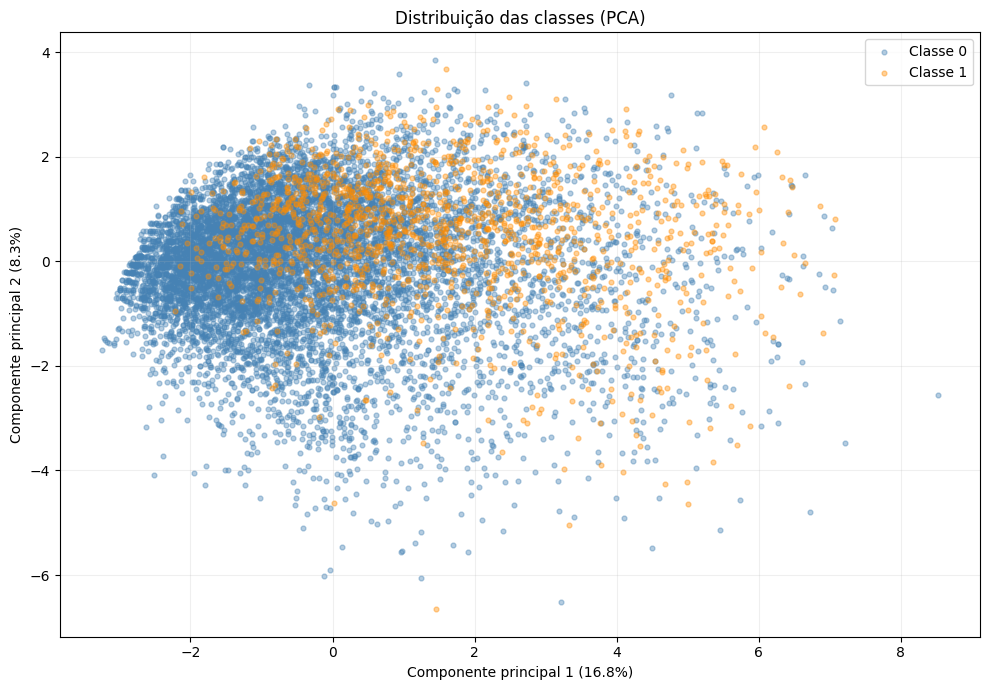

Variância explicada pelas duas componentes: 25.17%


In [ ]:
# Gráfico PCA

# Escalonamento dos atributos
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X_amostra)

# Redução para duas dimensões
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Gráfico
plt.figure(figsize=(10, 7))

# Identifica automaticamente as classes
classes = np.unique(np.asarray(Y_amostra).ravel())

# Define as cores
cores = ["steelblue", "darkorange"]

for i, classe in enumerate(classes):
    cor = cores[i % len(cores)]
    nome = f"Classe {classe}"

    mascara = np.asarray(Y_amostra).ravel() == classe

    plt.scatter(
        X_pca[mascara, 0],
        X_pca[mascara, 1],
        c=cor,
        label=nome,
        alpha=0.4,
        s=12
    )

plt.xlabel(
    f"Componente principal 1 "
    f"({pca.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"Componente principal 2 "
    f"({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("Distribuição das classes (PCA)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "Variância explicada pelas duas componentes:",
    f"{sum(pca.explained_variance_ratio_)*100:.2f}%"
)